In [ ]:
!pip -q install yfinance

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from pathlib import Path

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

In [ ]:
# ============================================================
# PROJECT CONFIGURATION
# ============================================================

START_DATE = "2007-01-01"

# Fixed data freeze for reproducibility.
# yfinance treats `end` as exclusive.
END_DATE_INCLUSIVE = "2026-10-12"
YF_END_DATE = "2026-10-13"

NIFTY_TICKER = "^NSEI"
NIFTYBEES_TICKER = "NIFTYBEES.NS"

# Protocol fallback until we replace it with historical RBI/FBIL data.
RISK_FREE_ANNUAL = 0.06

TRADING_DAYS = 252

DATA_DIR = Path("data")
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Project folders created.")

Project folders created.


In [ ]:
def download_yahoo_ohlcv(ticker, start, end):
    """
    Download daily OHLCV data from Yahoo Finance.

    auto_adjust=False is explicit so that:
    - raw OHLC prices remain available,
    - Adjusted Close remains separately available.
    """

    df = yf.download(
        ticker,
        start=start,
        end=end,
        auto_adjust=False,
        progress=False
    )

    if df.empty:
        raise ValueError(f"No data returned for {ticker}")

    # Recent yfinance versions can return MultiIndex columns
    # even for a single ticker.
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = [
            col[0] if isinstance(col, tuple) else col
            for col in df.columns
        ]

    df = df.copy()

    # Make DatetimeIndex clean and timezone-naive
    df.index = pd.to_datetime(df.index)

    if df.index.tz is not None:
        df.index = df.index.tz_localize(None)

    df.index.name = "Date"

    # Standardize names
    rename_map = {
        "Adj Close": "Adj_Close"
    }
    df = df.rename(columns=rename_map)

    expected = ["Open", "High", "Low", "Close", "Adj_Close", "Volume"]

    # Keep only columns that actually exist
    df = df[[c for c in expected if c in df.columns]]

    df = df.sort_index()

    return df

In [ ]:
nifty_raw = download_yahoo_ohlcv(
    NIFTY_TICKER,
    START_DATE,
    YF_END_DATE
)

niftybees_raw = download_yahoo_ohlcv(
    NIFTYBEES_TICKER,
    START_DATE,
    YF_END_DATE
)

print("NIFTY:")
display(nifty_raw.head())
display(nifty_raw.tail())

print("\nNIFTYBEES:")
display(niftybees_raw.head())
display(niftybees_raw.tail())

NIFTY:


,Open,High,Low,Close,Adj_Close,Volume
Date,,,,,,
2007-09-17,4518.450195,4549.049805,4482.850098,4494.649902,4494.649902,0
2007-09-18,4494.100098,4551.799805,4481.549805,4546.200195,4546.200195,0
2007-09-19,4550.250000,4739.000000,4550.250000,4732.350098,4732.350098,0
2007-09-20,4734.850098,4760.850098,4721.149902,4747.549805,4747.549805,0
2007-09-21,4752.950195,4855.700195,4733.700195,4837.549805,4837.549805,0


,Open,High,Low,Close,Adj_Close,Volume
Date,,,,,,
2026-10-06,22603.250000,22776.099609,22561.599609,22776.099609,22776.099609,328800
2026-10-07,22690.449219,22717.650391,22546.300781,22603.050781,22603.050781,359000
2026-10-08,22599.050781,22599.050781,22179.900391,22231.800781,22231.800781,357500
2026-10-09,22314.949219,22580.750000,22294.750000,22520.449219,22520.449219,296200
2026-10-12,22593.199219,22651.099609,22304.449219,22363.349609,22363.349609,0



NIFTYBEES:


,Open,High,Low,Close,Adj_Close,Volume
Date,,,,,,
2009-01-02,30.600000,30.945000,30.299999,30.556000,30.556000,1344830
2009-01-05,30.700001,31.370001,30.700001,31.174999,31.174999,2429180
2009-01-06,31.100000,31.480000,30.603001,31.124001,31.124001,1418730
2009-01-07,31.379999,31.500000,28.900000,29.264999,29.264999,5724640
2009-01-09,29.000000,29.500000,28.030001,28.855000,28.855000,1820800


,Open,High,Low,Close,Adj_Close,Volume
Date,,,,,,
2026-10-06,258.859985,259.250000,255.800003,258.890015,258.890015,7681670
2026-10-07,258.589996,258.989990,257.130005,257.589996,257.589996,5897585
2026-10-08,258.690002,258.690002,253.369995,253.759995,253.759995,10595383
2026-10-09,256.290009,257.700012,253.929993,257.350006,257.350006,5570363
2026-10-12,257.350006,258.679993,254.500000,254.660004,254.660004,8975770


In [ ]:
nifty_raw.to_csv(RAW_DIR / "nifty50_yahoo_raw.csv")
niftybees_raw.to_csv(RAW_DIR / "niftybees_yahoo_raw.csv")

print("Raw files saved:")
print(RAW_DIR / "nifty50_yahoo_raw.csv")
print(RAW_DIR / "niftybees_yahoo_raw.csv")

Raw files saved:
data/raw/nifty50_yahoo_raw.csv
data/raw/niftybees_yahoo_raw.csv


In [ ]:
def sanity_check_ohlcv(df, name):
    print("=" * 70)
    print(name)
    print("=" * 70)

    print(f"Start date       : {df.index.min().date()}")
    print(f"End date         : {df.index.max().date()}")
    print(f"Observations     : {len(df):,}")
    print(f"Duplicate dates  : {df.index.duplicated().sum()}")

    print("\nMissing values:")
    print(df.isna().sum())

    price_cols = [
        c for c in ["Open", "High", "Low", "Close", "Adj_Close"]
        if c in df.columns
    ]

    nonpositive = (df[price_cols] <= 0).sum()
    print("\nNon-positive price counts:")
    print(nonpositive)

    # Basic OHLC consistency
    if {"Open", "High", "Low", "Close"}.issubset(df.columns):

        bad_high = (
            df["High"] <
            df[["Open", "Close", "Low"]].max(axis=1)
        )

        bad_low = (
            df["Low"] >
            df[["Open", "Close", "High"]].min(axis=1)
        )

        print(f"\nInvalid High rows : {bad_high.sum()}")
        print(f"Invalid Low rows  : {bad_low.sum()}")

    # Largest calendar gaps
    gaps = df.index.to_series().diff().dt.days

    print("\nLargest calendar gaps:")
    print(gaps.nlargest(10))

    # Temporary return diagnostics
    price_col = "Adj_Close" if "Adj_Close" in df.columns else "Close"

    ret = df[price_col].pct_change()

    print("\nSimple return diagnostics:")
    print(ret.describe())

    print("\nLargest absolute daily returns:")
    print(ret.abs().nlargest(10))

    print()

In [ ]:
sanity_check_ohlcv(nifty_raw, "NIFTY 50")
sanity_check_ohlcv(niftybees_raw, "NIFTYBEES")

NIFTY 50
Start date       : 2007-09-17
End date         : 2026-10-12
Observations     : 4,678
Duplicate dates  : 0

Missing values:
Open         0
High         0
Low          0
Close        0
Adj_Close    0
Volume       0
dtype: int64

Non-positive price counts:
Open         0
High         0
Low          0
Close        0
Adj_Close    0
dtype: int64

Invalid High rows : 0
Invalid Low rows  : 0

Largest calendar gaps:
Date
2014-10-07    6.0
2008-03-24    5.0
2009-05-04    5.0
2009-12-29    5.0
2012-04-09    5.0
2014-10-27    5.0
2015-04-06    5.0
2016-03-28    5.0
2016-04-18    5.0
2016-08-16    5.0
Name: Date, dtype: float64

Simple return diagnostics:
count    4677.000000
mean        0.000427
std         0.012918
min        -0.129805
25%        -0.005233
50%         0.000552
75%         0.006496
max         0.177441
Name: Adj_Close, dtype: float64

Largest absolute daily returns:
Date
2009-05-18    0.177441
2020-03-23    0.129805
2008-10-24    0.122029
2020-04-07    0.087632
2008-01-21

In [ ]:
def build_return_dataset(df):
    out = df.copy()

    # For Yahoo data, use adjusted close for return calculations where possible.
    # If we later replace the NIFTY series with official TRI data,
    # TRI itself becomes the Price series.
    if "Adj_Close" in out.columns:
        out["Price"] = out["Adj_Close"]
    else:
        out["Price"] = out["Close"]

    # Simple return for portfolio P&L
    out["Return"] = out["Price"].pct_change()

    # Log return for volatility/statistical work
    out["Log_Return"] = np.log(
        out["Price"] / out["Price"].shift(1)
    )

    return out

In [ ]:
nifty = build_return_dataset(nifty_raw)
niftybees = build_return_dataset(niftybees_raw)

display(
    nifty[
        ["Open", "High", "Low", "Close", "Price", "Return", "Log_Return"]
    ].head(10)
)

,Open,High,Low,Close,Price,Return,Log_Return
Date,,,,,,,
2007-09-17,4518.450195,4549.049805,4482.850098,4494.649902,4494.649902,NaN,NaN
2007-09-18,4494.100098,4551.799805,4481.549805,4546.200195,4546.200195,0.011469,0.011404
2007-09-19,4550.250000,4739.000000,4550.250000,4732.350098,4732.350098,0.040946,0.040130
2007-09-20,4734.850098,4760.850098,4721.149902,4747.549805,4747.549805,0.003212,0.003207
2007-09-21,4752.950195,4855.700195,4733.700195,4837.549805,4837.549805,0.018957,0.018780
2007-09-24,4837.149902,4941.149902,4837.149902,4932.200195,4932.200195,0.019566,0.019377
2007-09-25,4939.100098,4953.899902,4878.149902,4938.850098,4938.850098,0.001348,0.001347
2007-09-26,4937.600098,4980.850098,4930.350098,4940.500000,4940.500000,0.000334,0.000334
2007-09-27,4942.700195,5016.399902,4942.700195,5000.549805,5000.549805,0.012155,0.012081


In [ ]:
rf_daily = (1 + RISK_FREE_ANNUAL) ** (1 / TRADING_DAYS) - 1

print(f"Annual risk-free fallback : {RISK_FREE_ANNUAL:.2%}")
print(f"Daily risk-free rate      : {rf_daily:.8f}")

Annual risk-free fallback : 6.00%
Daily risk-free rate      : 0.00023125


In [ ]:
nifty["RF_Return"] = rf_daily
niftybees["RF_Return"] = rf_daily

nifty["Excess_Return"] = nifty["Return"] - nifty["RF_Return"]
niftybees["Excess_Return"] = niftybees["Return"] - niftybees["RF_Return"]

In [ ]:
nifty["RF_Return"] = actual_rf_series

NameError: name 'actual_rf_series' is not defined

In [ ]:
def return_integrity_report(df, name):
    print("=" * 70)
    print(name)
    print("=" * 70)

    clean = df["Return"].dropna()

    print(f"Return observations : {len(clean):,}")
    print(f"Mean daily return   : {clean.mean():.6f}")
    print(f"Daily volatility    : {clean.std():.6f}")

    annual_return_approx = clean.mean() * 252
    annual_vol = clean.std() * np.sqrt(252)

    print(f"Approx ann. return  : {annual_return_approx:.2%}")
    print(f"Annualized vol      : {annual_vol:.2%}")

    print(f"\nMinimum daily return: {clean.min():.2%}")
    print(f"Maximum daily return: {clean.max():.2%}")

    print("\nDates of five largest absolute returns:")
    print(
        df.loc[
            clean.abs().nlargest(5).index,
            ["Price", "Return"]
        ]
    )

    print()

In [ ]:
return_integrity_report(nifty, "NIFTY 50")
return_integrity_report(niftybees, "NIFTYBEES")

NIFTY 50
Return observations : 4,677
Mean daily return   : 0.000427
Daily volatility    : 0.012918
Approx ann. return  : 10.75%
Annualized vol      : 20.51%

Minimum daily return: -12.98%
Maximum daily return: 17.74%

Dates of five largest absolute returns:
                  Price    Return
Date                             
2009-05-18  4323.149902  0.177441
2020-03-23  7610.250000 -0.129805
2008-10-24  2584.000000 -0.122029
2020-04-07  8792.200195  0.087632
2008-01-21  5208.799805 -0.087024

NIFTYBEES
Return observations : 4,380
Mean daily return   : 0.002390
Daily volatility    : 0.136659
Approx ann. return  : 60.22%
Annualized vol      : 216.94%

Minimum daily return: -89.93%
Maximum daily return: 896.85%

Dates of five largest absolute returns:
                 Price    Return
Date                            
2019-12-23  129.929993  8.968543
2019-12-19   13.020000 -0.899268
2010-10-07   61.619999  0.173714
2010-10-06   52.500000 -0.154589
2009-05-18   42.757000  0.146270



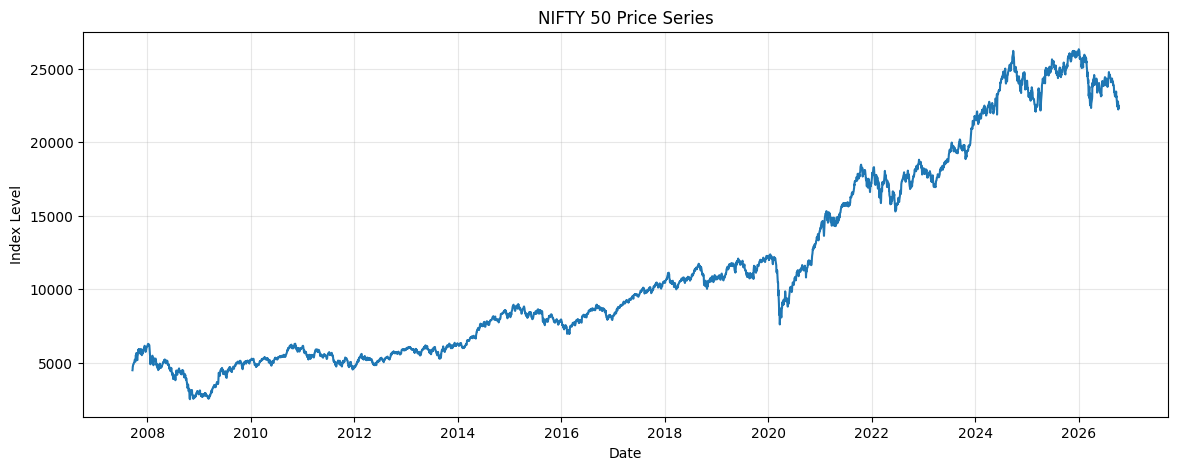

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(nifty.index, nifty["Price"])
plt.title("NIFTY 50 Price Series")
plt.xlabel("Date")
plt.ylabel("Index Level")
plt.grid(alpha=0.3)
plt.show()

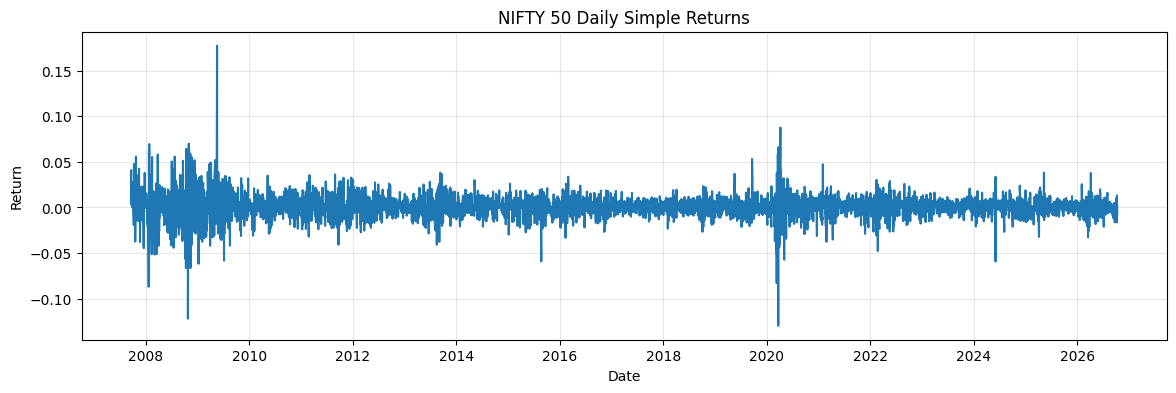

In [ ]:
plt.figure(figsize=(14, 4))
plt.plot(nifty.index, nifty["Return"])
plt.title("NIFTY 50 Daily Simple Returns")
plt.xlabel("Date")
plt.ylabel("Return")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
nifty.to_csv(
    PROCESSED_DIR / "nifty50_processed.csv"
)

niftybees.to_csv(
    PROCESSED_DIR / "niftybees_processed.csv"
)

print("Processed datasets saved.")

Processed datasets saved.


In [ ]:
def dataset_summary(df, name):
    r = df["Return"].dropna()

    return {
        "Dataset": name,
        "Start": df.index.min().date(),
        "End": df.index.max().date(),
        "Rows": len(df),
        "Missing_Returns": df["Return"].isna().sum(),
        "Mean_Daily_Return": r.mean(),
        "Daily_Vol": r.std(),
        "Annualized_Vol": r.std() * np.sqrt(252),
        "Min_Return": r.min(),
        "Max_Return": r.max()
    }


summary = pd.DataFrame([
    dataset_summary(nifty, "NIFTY 50"),
    dataset_summary(niftybees, "NIFTYBEES")
])

display(summary)

,Dataset,Start,End,Rows,Missing_Returns,Mean_Daily_Return,Daily_Vol,Annualized_Vol,Min_Return,Max_Return
0,NIFTY 50,2007-09-17,2026-10-12,4678,1,0.000427,0.012918,0.205070,-0.129805,0.177441
1,NIFTYBEES,2009-01-02,2026-10-12,4381,1,0.002390,0.136659,2.169389,-0.899268,8.968543


In [ ]:
print("NIFTY missing values:")
print(nifty.isna().sum())

print("\nNIFTY five largest absolute-return days:")
display(
    nifty.loc[
        nifty["Return"].abs().nlargest(5).index,
        ["Open", "High", "Low", "Close", "Price", "Return"]
    ]
)

NIFTY missing values:
Open             0
High             0
Low              0
Close            0
Adj_Close        0
Volume           0
Price            0
Return           1
Log_Return       1
RF_Return        0
Excess_Return    1
dtype: int64

NIFTY five largest absolute-return days:


,Open,High,Low,Close,Price,Return
Date,,,,,,
2009-05-18,3673.149902,4384.299805,3673.149902,4323.149902,4323.149902,0.177441
2020-03-23,7945.700195,8159.250000,7583.600098,7610.250000,7610.250000,-0.129805
2008-10-24,2936.250000,2936.250000,2525.050049,2584.000000,2584.000000,-0.122029
2020-04-07,8446.299805,8819.400391,8360.950195,8792.200195,8792.200195,0.087632
2008-01-21,5705.000000,5705.000000,4977.100098,5208.799805,5208.799805,-0.087024


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats

r = nifty["Log_Return"].dropna().copy()

# Percentage units are easier to read.
r_pct = 100 * r

print(f"Observations: {len(r_pct):,}")
print(r_pct.head())

Observations: 4,677
Date
2007-09-18    1.140398
2007-09-19    4.013017
2007-09-20    0.320673
2007-09-21    1.877970
2007-09-24    1.937682
Name: Log_Return, dtype: float64


In [ ]:
summary_stats = pd.Series({
    "Mean (%)": r_pct.mean(),
    "Median (%)": r_pct.median(),
    "Std Dev (%)": r_pct.std(),
    "Skewness": stats.skew(r_pct, bias=False),
    "Excess Kurtosis": stats.kurtosis(r_pct, fisher=True, bias=False),
    "Min (%)": r_pct.min(),
    "1% Quantile (%)": r_pct.quantile(0.01),
    "5% Quantile (%)": r_pct.quantile(0.05),
    "95% Quantile (%)": r_pct.quantile(0.95),
    "99% Quantile (%)": r_pct.quantile(0.99),
    "Max (%)": r_pct.max(),
})

display(summary_stats.to_frame("Value"))

,Value
Mean (%),0.034307
Median (%),0.055205
Std Dev (%),1.292577
Skewness,-0.277823
Excess Kurtosis,15.188422
Min (%),-13.903756
1% Quantile (%),-3.621936
5% Quantile (%),-1.843577
95% Quantile (%),1.847886
99% Quantile (%),3.514065


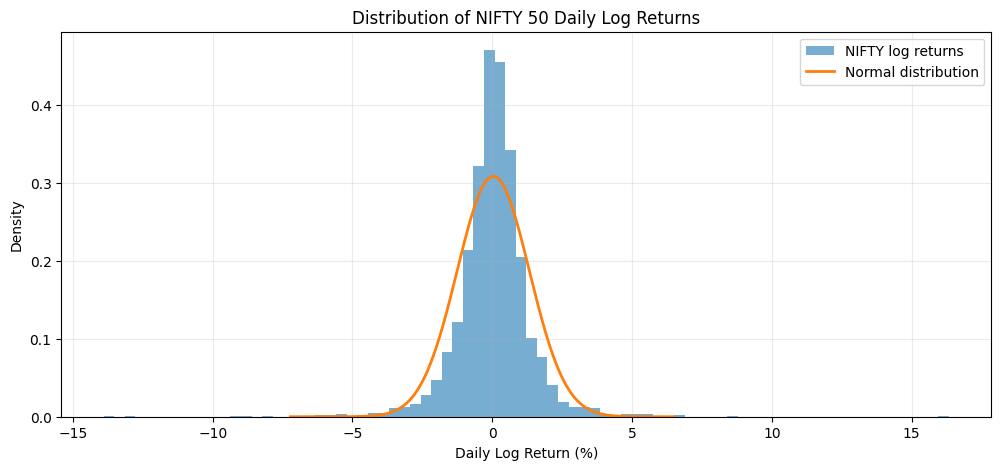

In [ ]:
mu = r_pct.mean()
sigma = r_pct.std()

x = np.linspace(
    r_pct.quantile(0.001),
    r_pct.quantile(0.999),
    500
)

normal_pdf = stats.norm.pdf(x, loc=mu, scale=sigma)

plt.figure(figsize=(12, 5))

plt.hist(
    r_pct,
    bins=80,
    density=True,
    alpha=0.6,
    label="NIFTY log returns"
)

plt.plot(
    x,
    normal_pdf,
    linewidth=2,
    label="Normal distribution"
)

plt.title("Distribution of NIFTY 50 Daily Log Returns")
plt.xlabel("Daily Log Return (%)")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

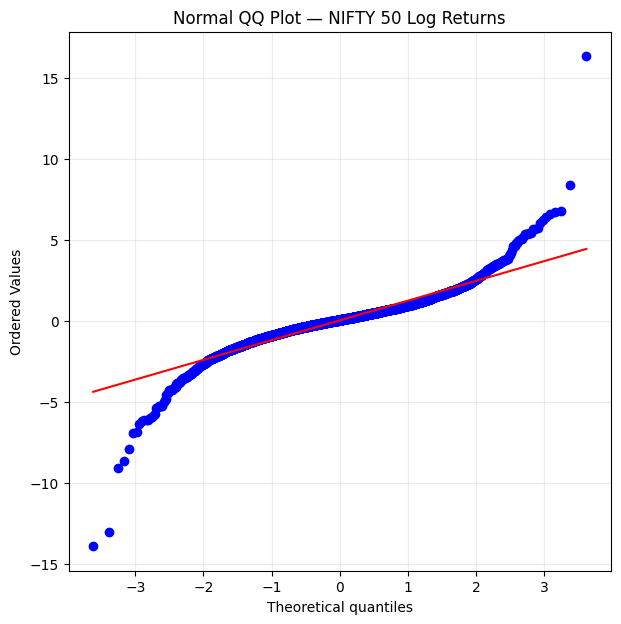

In [ ]:
plt.figure(figsize=(7, 7))

stats.probplot(
    r_pct,
    dist="norm",
    plot=plt
)

plt.title("Normal QQ Plot — NIFTY 50 Log Returns")
plt.grid(alpha=0.25)
plt.show()

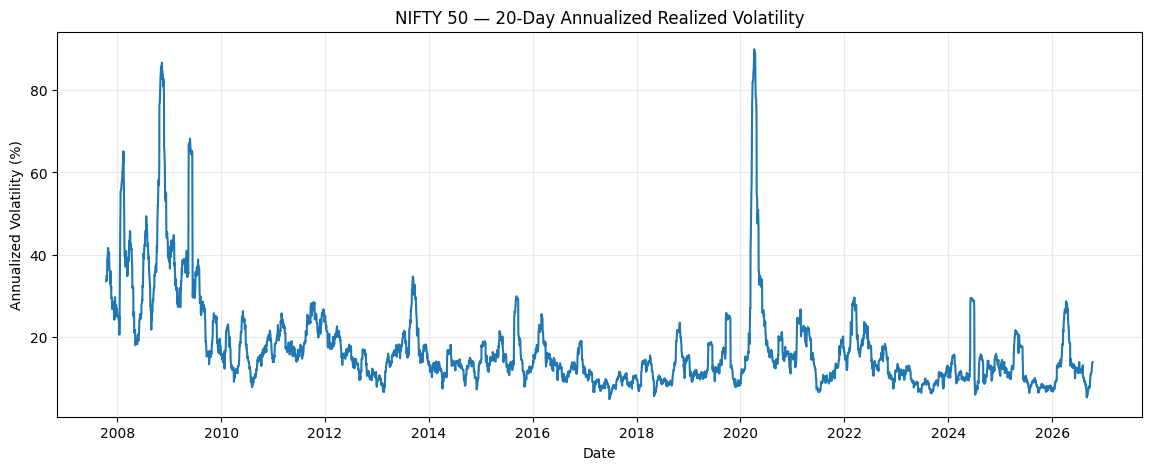

In [ ]:
rolling_var_20 = r.pow(2).rolling(20).mean()

rolling_vol_20_ann = (
    np.sqrt(rolling_var_20) * np.sqrt(252)
)

plt.figure(figsize=(14, 5))
plt.plot(
    rolling_vol_20_ann.index,
    rolling_vol_20_ann * 100
)

plt.title("NIFTY 50 — 20-Day Annualized Realized Volatility")
plt.xlabel("Date")
plt.ylabel("Annualized Volatility (%)")
plt.grid(alpha=0.25)
plt.show()

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf

<Figure size 1200x500 with 0 Axes>

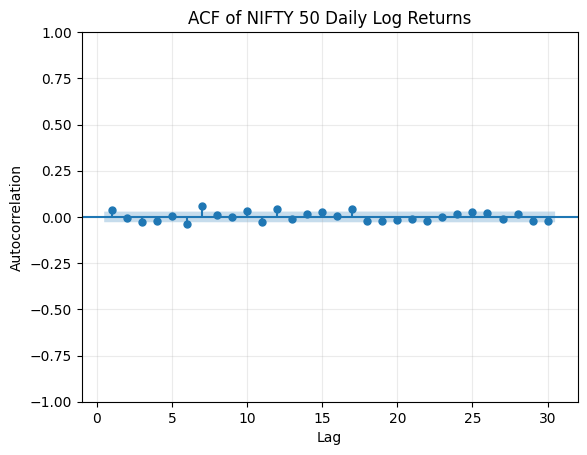

In [ ]:
plt.figure(figsize=(12, 5))

plot_acf(
    r_pct,
    lags=30,
    zero=False
)

plt.title("ACF of NIFTY 50 Daily Log Returns")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")
plt.grid(alpha=0.25)
plt.show()

<Figure size 1200x500 with 0 Axes>

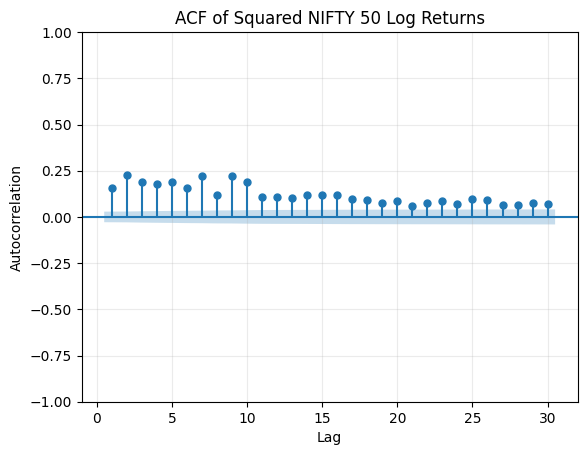

In [ ]:
plt.figure(figsize=(12, 5))

plot_acf(
    r_pct ** 2,
    lags=30,
    zero=False
)

plt.title("ACF of Squared NIFTY 50 Log Returns")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")
plt.grid(alpha=0.25)
plt.show()

In [ ]:
from statsmodels.tsa.stattools import acf

lags_to_show = [1, 2, 5, 10, 20]

acf_returns = acf(
    r_pct,
    nlags=max(lags_to_show),
    fft=True
)

acf_squared = acf(
    r_pct ** 2,
    nlags=max(lags_to_show),
    fft=True
)

acf_table = pd.DataFrame({
    "Lag": lags_to_show,
    "Return_ACF": [acf_returns[i] for i in lags_to_show],
    "Squared_Return_ACF": [acf_squared[i] for i in lags_to_show]
})

display(acf_table)

,Lag,Return_ACF,Squared_Return_ACF
0,1,0.036669,0.158978
1,2,-0.006138,0.225716
2,5,0.003587,0.187723
3,10,0.029716,0.187343
4,20,-0.018696,0.088105


In [ ]:
from statsmodels.stats.diagnostic import acorr_ljungbox

In [ ]:
lb_returns = acorr_ljungbox(
    r_pct,
    lags=[5, 10, 20],
    return_df=True
)

print("Ljung-Box Test — Raw Returns")
display(lb_returns)

Ljung-Box Test — Raw Returns


,lb_stat,lb_pvalue
5,12.235992,3.169339e-02
10,39.462069,2.106782e-05
20,71.717028,9.527868e-08


In [ ]:
lb_squared = acorr_ljungbox(
    r_pct ** 2,
    lags=[5, 10, 20],
    return_df=True
)

print("Ljung-Box Test — Squared Returns")
display(lb_squared)

Ljung-Box Test — Squared Returns


,lb_stat,lb_pvalue
5,834.985144,3.120155e-178
10,1637.729418,0.000000e+00
20,2139.640572,0.000000e+00


In [ ]:
from statsmodels.stats.diagnostic import het_arch

arch_results = []

for lag in [5, 10, 20]:
    lm_stat, lm_pvalue, f_stat, f_pvalue = het_arch(
        r_pct,
        nlags=lag
    )

    arch_results.append({
        "Lags": lag,
        "LM Statistic": lm_stat,
        "LM p-value": lm_pvalue,
        "F Statistic": f_stat,
        "F p-value": f_pvalue
    })

arch_table = pd.DataFrame(arch_results)

display(arch_table)

/usr/local/lib/python3.13/dist-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,Lags,LM Statistic,LM p-value,F Statistic,F p-value
0,5,485.092705,1.317336e-102,108.120023,2.412884e-108
1,10,655.995920,1.741333e-134,76.148439,3.458088e-145
2,20,669.215081,7.155742e-129,38.899805,9.723670e-140


In [ ]:
stage2_summary = {
    "Observations": len(r_pct),
    "Mean_Daily_Log_Return_pct": r_pct.mean(),
    "Std_Daily_Log_Return_pct": r_pct.std(),
    "Skewness": stats.skew(r_pct, bias=False),
    "Excess_Kurtosis": stats.kurtosis(
        r_pct,
        fisher=True,
        bias=False
    ),
    "ACF_Return_Lag1": acf_returns[1],
    "ACF_Squared_Return_Lag1": acf_squared[1],
    "LB_Return_20_pvalue": lb_returns.loc[20, "lb_pvalue"],
    "LB_Squared_20_pvalue": lb_squared.loc[20, "lb_pvalue"],
    "ARCH_LM_20_pvalue": arch_table.loc[
        arch_table["Lags"] == 20,
        "LM p-value"
    ].iloc[0]
}

stage2_summary = pd.Series(stage2_summary)

display(stage2_summary.to_frame("Value"))

,Value
Observations,4.677000e+03
Mean_Daily_Log_Return_pct,3.430694e-02
Std_Daily_Log_Return_pct,1.292577e+00
Skewness,-2.778233e-01
Excess_Kurtosis,1.518842e+01
ACF_Return_Lag1,3.666887e-02
ACF_Squared_Return_Lag1,1.589784e-01
LB_Return_20_pvalue,9.527868e-08
LB_Squared_20_pvalue,0.000000e+00
ARCH_LM_20_pvalue,7.155742e-129


In [ ]:
bees_outliers = niftybees_raw.copy()

bees_outliers["Close_Return"] = (
    bees_outliers["Close"].pct_change()
)

bees_outliers["Adj_Return"] = (
    bees_outliers["Adj_Close"].pct_change()
)

bees_outliers["Adjustment_Factor"] = (
    bees_outliers["Adj_Close"] /
    bees_outliers["Close"]
)

idx = (
    bees_outliers["Adj_Return"]
    .abs()
    .nlargest(10)
    .index
)

display(
    bees_outliers.loc[
        idx,
        [
            "Open",
            "High",
            "Low",
            "Close",
            "Adj_Close",
            "Close_Return",
            "Adj_Return",
            "Adjustment_Factor"
        ]
    ].sort_index()
)

,Open,High,Low,Close,Adj_Close,Close_Return,Adj_Return,Adjustment_Factor
Date,,,,,,,,
2009-05-18,40.000000,44.500000,40.000000,42.757000,42.757000,0.146270,0.146270,1.0
2010-02-05,48.599998,54.500000,47.799999,54.500000,54.500000,0.107724,0.107724,1.0
2010-02-08,47.514999,48.500000,47.505001,48.205002,48.205002,-0.115505,-0.115505,1.0
2010-10-06,62.200001,62.485001,52.500000,52.500000,52.500000,-0.154589,-0.154589,1.0
2010-10-07,63.500000,63.500000,61.415001,61.619999,61.619999,0.173714,0.173714,1.0
2019-12-19,12.920000,13.033000,12.905000,13.020000,13.020000,-0.899268,-0.899268,1.0
2019-12-23,131.199997,131.250000,129.279999,129.929993,129.929993,8.968543,8.968543,1.0
2020-03-12,110.000000,110.000000,101.050003,102.989998,102.989998,-0.074746,-0.074746,1.0
2020-03-19,94.500000,94.500000,87.000000,89.470001,89.470001,-0.068797,-0.068797,1.0


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TRADING_DAYS = 252

ROLLING_WINDOW = 20
EWMA_LAMBDA = 0.94

r = nifty["Log_Return"].copy()

# Squared daily log return in DECIMAL units.
# Example: 2% return = 0.02, squared = 0.0004.
r2 = r ** 2

In [ ]:
rolling20_var_forecast = (
    r2
    .rolling(
        window=ROLLING_WINDOW,
        min_periods=ROLLING_WINDOW
    )
    .mean()
)

In [ ]:
rolling20_vol_daily = np.sqrt(
    rolling20_var_forecast
)

In [ ]:
rolling20_vol_annual = (
    rolling20_vol_daily *
    np.sqrt(TRADING_DAYS)
)

In [ ]:
def ewma_variance_forecast(
    returns,
    lam=0.94,
    initial_window=20
):
    """
    Produces variance forecasts stored on creation date t.

    Output at date t means:

        sigma_hat^2_{t+1 | t}

    i.e. forecast of next day's variance using information
    available through date t.
    """

    returns = returns.dropna()

    squared_returns = returns ** 2

    forecasts = pd.Series(
        np.nan,
        index=returns.index,
        dtype=float
    )

    if len(returns) < initial_window:
        raise ValueError(
            "Not enough observations for EWMA initialization."
        )

    # Initial estimate:
    # average squared return over the first 20 observations.
    seed_position = initial_window - 1
    seed_date = returns.index[seed_position]

    initial_variance = (
        squared_returns
        .iloc[:initial_window]
        .mean()
    )

    forecasts.loc[seed_date] = initial_variance

    # Recursive updating
    for i in range(initial_window, len(returns)):

        current_date = returns.index[i]
        previous_date = returns.index[i - 1]

        previous_forecast = forecasts.loc[
            previous_date
        ]

        current_squared_return = (
            squared_returns.iloc[i]
        )

        forecasts.loc[current_date] = (
            lam * previous_forecast
            +
            (1 - lam) * current_squared_return
        )

    # Put back onto original calendar/index
    return forecasts.reindex(
        r.index
    )

In [ ]:
ewma94_var_forecast = ewma_variance_forecast(
    r,
    lam=EWMA_LAMBDA,
    initial_window=20
)

In [ ]:
ewma94_vol_daily = np.sqrt(
    ewma94_var_forecast
)

ewma94_vol_annual = (
    ewma94_vol_daily *
    np.sqrt(TRADING_DAYS)
)

In [ ]:
vol_forecasts = pd.DataFrame({
    "Return": r,
    "Squared_Return": r2,

    "Rolling20_Var_Forecast":
        rolling20_var_forecast,

    "EWMA94_Var_Forecast":
        ewma94_var_forecast,

    "Rolling20_Ann_Vol":
        rolling20_vol_annual,

    "EWMA94_Ann_Vol":
        ewma94_vol_annual
})

In [ ]:
vol_forecasts["Next_Day_Squared_Return"] = (
    r2.shift(-1)
)

In [ ]:
display(
    vol_forecasts.dropna().head(10)
)

,Return,Squared_Return,Rolling20_Var_Forecast,EWMA94_Var_Forecast,Rolling20_Ann_Vol,EWMA94_Ann_Vol,Next_Day_Squared_Return
Date,,,,,,,
2007-10-16,-0.000415,1.718401e-07,0.000448,0.000448,0.336010,0.336010,0.000375
2007-10-17,-0.019373,3.753109e-04,0.000460,0.000444,0.340577,0.334369,0.001458
2007-10-18,-0.038189,1.458377e-03,0.000453,0.000505,0.337753,0.356575,0.000660
2007-10-19,-0.025687,6.598160e-04,0.000485,0.000514,0.349658,0.359852,0.000036
2007-10-22,-0.006020,3.623578e-05,0.000469,0.000485,0.343910,0.349673,0.002957
2007-10-23,0.054378,2.956954e-03,0.000598,0.000634,0.388330,0.399555,0.000017
2007-10-24,0.004093,1.675256e-05,0.000599,0.000597,0.388573,0.387710,0.000173
2007-10-25,0.013159,1.731522e-04,0.000608,0.000571,0.391368,0.379365,0.000560
2007-10-26,0.023663,5.599379e-04,0.000629,0.000570,0.397976,0.379143,0.001231


In [ ]:
half_life = (
    np.log(0.5) /
    np.log(EWMA_LAMBDA)
)

print(
    f"EWMA lambda: {EWMA_LAMBDA}"
)

print(
    f"EWMA variance-shock half-life: "
    f"{half_life:.2f} trading days"
)

EWMA lambda: 0.94
EWMA variance-shock half-life: 11.20 trading days


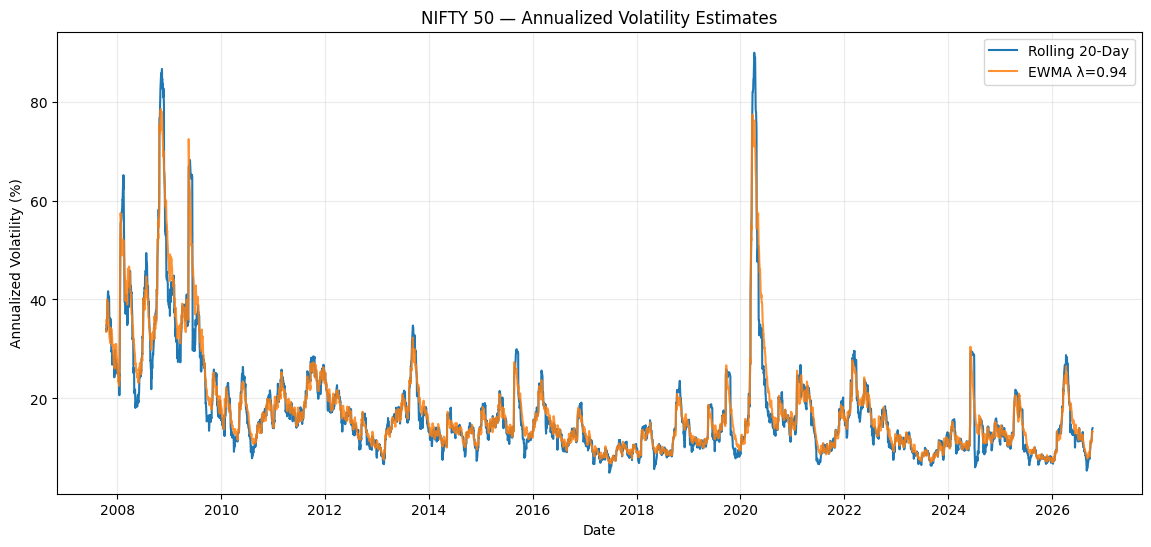

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    vol_forecasts.index,
    100 * vol_forecasts[
        "Rolling20_Ann_Vol"
    ],
    label="Rolling 20-Day"
)

plt.plot(
    vol_forecasts.index,
    100 * vol_forecasts[
        "EWMA94_Ann_Vol"
    ],
    label="EWMA λ=0.94",
    alpha=0.85
)

plt.title(
    "NIFTY 50 — Annualized Volatility Estimates"
)

plt.xlabel("Date")
plt.ylabel("Annualized Volatility (%)")

plt.legend()
plt.grid(alpha=0.25)

plt.show()

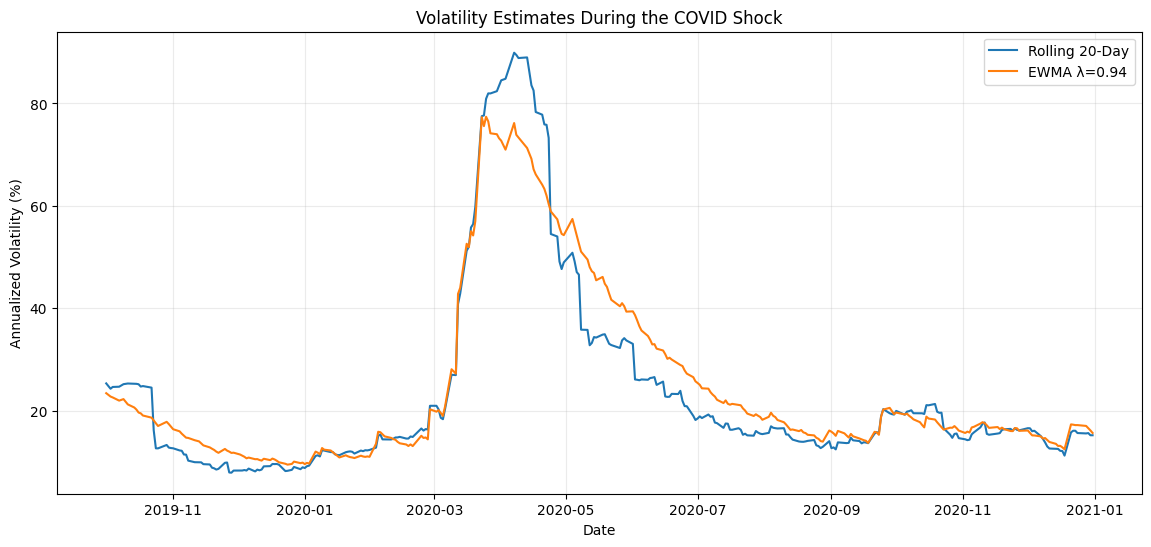

In [ ]:
covid = vol_forecasts.loc[
    "2019-10-01":"2020-12-31"
]

plt.figure(figsize=(14, 6))

plt.plot(
    covid.index,
    100 * covid["Rolling20_Ann_Vol"],
    label="Rolling 20-Day"
)

plt.plot(
    covid.index,
    100 * covid["EWMA94_Ann_Vol"],
    label="EWMA λ=0.94"
)

plt.title(
    "Volatility Estimates During the COVID Shock"
)

plt.xlabel("Date")
plt.ylabel("Annualized Volatility (%)")

plt.legend()
plt.grid(alpha=0.25)

plt.show()

In [ ]:
def volatility_summary(series):
    clean = series.dropna()

    max_date = clean.idxmax()

    return {
        "Start": clean.index.min().date(),
        "Mean_Ann_Vol": clean.mean(),
        "Median_Ann_Vol": clean.median(),
        "Max_Ann_Vol": clean.max(),
        "Max_Vol_Date": max_date.date()
    }


vol_summary = pd.DataFrame({
    "Rolling20": volatility_summary(
        rolling20_vol_annual
    ),

    "EWMA94": volatility_summary(
        ewma94_vol_annual
    )
}).T

display(vol_summary)

,Start,Mean_Ann_Vol,Median_Ann_Vol,Max_Ann_Vol,Max_Vol_Date
Rolling20,2007-10-16,0.172705,0.141767,0.899008,2020-04-07
EWMA94,2007-10-16,0.17625,0.145243,0.785304,2008-11-03


In [ ]:
display(
    vol_forecasts.loc[
        "2020-03-01":"2020-04-30",
        [
            "Return",
            "Rolling20_Ann_Vol",
            "EWMA94_Ann_Vol"
        ]
    ].tail(30)
)

,Return,Rolling20_Ann_Vol,EWMA94_Ann_Vol
Date,,,
2020-03-16,-0.079174,0.512303,0.525861
2020-03-17,-0.025364,0.519847,0.519293
2020-03-18,-0.057168,0.557696,0.550364
2020-03-19,-0.024547,0.564242,0.542067
2020-03-20,0.056691,0.597764,0.569913
2020-03-23,-0.139038,0.775064,0.773049
2020-03-24,0.024762,0.776450,0.755658
2020-03-25,0.064145,0.809092,0.773932
2020-03-26,0.038167,0.819561,0.764891


In [ ]:
vol_forecasts.to_csv(
    PROCESSED_DIR /
    "nifty50_rolling_ewma_forecasts.csv"
)

print(
    "Rolling and EWMA forecasts saved."
)

Rolling and EWMA forecasts saved.


In [ ]:
!pip -q install arch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 3.0 MB/s eta 0:00:00


In [ ]:
from arch import arch_model

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
def garch11_monthly_walkforward(
    returns,
    oos_start="2015-01-01"
):
    """
    Expanding-window GARCH(1,1) forecasting.

    Model:
        h_{t+1} = omega + alpha * r_t^2 + beta * h_t

    where returns are fitted in PERCENT units.

    Forecast output is stored on CREATION DATE t:

        output[t] = variance forecast for day t+1
                    using information through day t.

    GARCH parameters are re-estimated once per calendar month.
    Between refits, variance is updated recursively each day
    using the fixed parameters.
    """

    # ----------------------------------------
    # Prepare returns
    # ----------------------------------------

    r = returns.dropna().copy()

    # Fit GARCH in percentage-return units
    r_pct = 100 * r

    dates = r_pct.index

    oos_start = pd.Timestamp(oos_start)

    first_oos_pos = dates.searchsorted(oos_start)

    if first_oos_pos <= 0:
        raise ValueError(
            "OOS start must occur after the beginning of the data."
        )

    # We need sufficient estimation history.
    if first_oos_pos < 500:
        raise ValueError(
            "Too little history before OOS period."
        )

    # Forecast variance in percentage-return-squared units initially
    forecast_var_pct2 = pd.Series(
        np.nan,
        index=dates,
        dtype=float
    )

    parameter_records = []

    # ----------------------------------------
    # Initial fit:
    # all data through the last date before 2015
    # ----------------------------------------

    initial_end_pos = first_oos_pos - 1

    initial_train = r_pct.iloc[
        :initial_end_pos + 1
    ]

    model = arch_model(
        initial_train,
        mean="Zero",
        vol="GARCH",
        p=1,
        q=1,
        dist="normal",
        rescale=False
    )

    result = model.fit(
        disp="off",
        update_freq=0
    )

    omega = result.params["omega"]
    alpha = result.params["alpha[1]"]
    beta = result.params["beta[1]"]

    # h_t for the final estimation observation
    h_t = (
        result.conditional_volatility.iloc[-1]
        ** 2
    )

    initial_date = dates[initial_end_pos]

    current_refit_month = (
        initial_date.year,
        initial_date.month
    )

    persistence = alpha + beta

    if persistence < 1:
        long_run_var_pct2 = (
            omega / (1 - persistence)
        )

        long_run_ann_vol = (
            np.sqrt(long_run_var_pct2)
            * np.sqrt(252)
            / 100
        )
    else:
        long_run_ann_vol = np.nan

    parameter_records.append({
        "Refit_Date": initial_date,
        "omega": omega,
        "alpha": alpha,
        "beta": beta,
        "alpha_plus_beta": persistence,
        "Long_Run_Ann_Vol": long_run_ann_vol
    })

    # ----------------------------------------
    # Walk forward
    # ----------------------------------------

    for i in range(
        initial_end_pos,
        len(r_pct) - 1
    ):

        current_date = dates[i]

        # ------------------------------------
        # Monthly parameter refit
        # ------------------------------------

        month_key = (
            current_date.year,
            current_date.month
        )

        # Do not immediately refit the initial model;
        # refit when we enter a new calendar month.
        if (
            i > initial_end_pos
            and month_key != current_refit_month
        ):

            train = r_pct.iloc[:i + 1]

            model = arch_model(
                train,
                mean="Zero",
                vol="GARCH",
                p=1,
                q=1,
                dist="normal",
                rescale=False
            )

            result = model.fit(
                disp="off",
                update_freq=0
            )

            omega = result.params["omega"]
            alpha = result.params["alpha[1]"]
            beta = result.params["beta[1]"]

            # Conditional variance on current date
            # from the newly fitted expanding-window model
            h_t = (
                result
                .conditional_volatility
                .iloc[-1] ** 2
            )

            current_refit_month = month_key

            persistence = alpha + beta

            if persistence < 1:
                long_run_var_pct2 = (
                    omega /
                    (1 - persistence)
                )

                long_run_ann_vol = (
                    np.sqrt(long_run_var_pct2)
                    * np.sqrt(252)
                    / 100
                )
            else:
                long_run_ann_vol = np.nan

            parameter_records.append({
                "Refit_Date": current_date,
                "omega": omega,
                "alpha": alpha,
                "beta": beta,
                "alpha_plus_beta": persistence,
                "Long_Run_Ann_Vol": long_run_ann_vol
            })

        # ------------------------------------
        # One-day-ahead variance forecast
        # ------------------------------------

        r_t_pct = r_pct.iloc[i]

        h_next = (
            omega
            + alpha * (r_t_pct ** 2)
            + beta * h_t
        )

        # Stored at t:
        # this is h_{t+1 | t}
        forecast_var_pct2.loc[
            current_date
        ] = h_next

        # Tomorrow's h_t becomes today's forecast
        h_t = h_next

    # ----------------------------------------
    # Convert from (% return)^2
    # back into decimal-return variance
    #
    # (100*r)^2 = 10,000*r^2
    # ----------------------------------------

    forecast_var_decimal = (
        forecast_var_pct2 /
        10_000
    )

    parameter_history = pd.DataFrame(
        parameter_records
    ).set_index("Refit_Date")

    return (
        forecast_var_decimal,
        parameter_history
    )

In [ ]:
garch11_var_forecast, garch_params = (
    garch11_monthly_walkforward(
        nifty["Log_Return"],
        oos_start="2015-01-01"
    )
)

In [ ]:
garch11_vol_daily = np.sqrt(
    garch11_var_forecast
)

garch11_vol_annual = (
    garch11_vol_daily *
    np.sqrt(252)
)

In [ ]:
display(
    garch_params.head(10)
)

,omega,alpha,beta,alpha_plus_beta,Long_Run_Ann_Vol
Refit_Date,,,,,
2014-12-31,0.013475,0.074201,0.921696,0.995898,0.287719
2015-01-02,0.013643,0.074387,0.921476,0.995863,0.288283
2015-02-02,0.014382,0.073937,0.921573,0.995510,0.284107
2015-03-02,0.014285,0.073620,0.921770,0.995390,0.279437
2015-04-01,0.014124,0.071989,0.923292,0.995281,0.274633
2015-05-04,0.013999,0.071408,0.923840,0.995248,0.272465
2015-06-01,0.014285,0.071692,0.923362,0.995054,0.269781
2015-07-01,0.014046,0.070897,0.924063,0.994960,0.265010
2015-08-03,0.013847,0.070180,0.924708,0.994888,0.261275


In [ ]:
display(
    garch_params.tail(10)
)

,omega,alpha,beta,alpha_plus_beta,Long_Run_Ann_Vol
Refit_Date,,,,,
2026-01-01,0.013565,0.090469,0.902756,0.993225,0.224620
2026-02-02,0.013628,0.090069,0.903020,0.993089,0.222911
2026-03-02,0.014071,0.090135,0.902618,0.992752,0.221185
2026-04-01,0.014273,0.092134,0.901050,0.993184,0.229725
2026-05-04,0.014546,0.092127,0.900586,0.992712,0.224272
2026-06-01,0.014673,0.092224,0.900274,0.992498,0.222004
2026-07-01,0.014636,0.091779,0.900581,0.992360,0.219720
2026-08-03,0.014618,0.090922,0.901343,0.992265,0.218226
2026-09-01,0.014190,0.091485,0.901070,0.992555,0.219159


In [ ]:
display(
    garch_params[
        [
            "alpha",
            "beta",
            "alpha_plus_beta",
            "Long_Run_Ann_Vol"
        ]
    ].describe()
)

,alpha,beta,alpha_plus_beta,Long_Run_Ann_Vol
count,143.000000,143.000000,143.000000,143.000000
mean,0.082305,0.911559,0.993864,0.242878
std,0.010459,0.011482,0.001513,0.018818
min,0.064739,0.897548,0.991270,0.216787
25%,0.071711,0.901309,0.992661,0.231040
50%,0.088545,0.905718,0.993555,0.239620
75%,0.091520,0.922080,0.995319,0.251070
max,0.095526,0.931951,0.997189,0.341129


In [ ]:
vol_forecasts[
    "GARCH11_Var_Forecast"
] = garch11_var_forecast

vol_forecasts[
    "GARCH11_Ann_Vol"
] = garch11_vol_annual

In [ ]:
display(
    vol_forecasts.loc[
        "2015-01-01":,
        [
            "Return",
            "Rolling20_Ann_Vol",
            "EWMA94_Ann_Vol",
            "GARCH11_Ann_Vol"
        ]
    ].dropna().head(10)
)

,Return,Rolling20_Ann_Vol,EWMA94_Ann_Vol,GARCH11_Ann_Vol
Date,,,,
2015-01-02,0.013521,0.145195,0.133858,0.148483
2015-01-05,-0.002033,0.144950,0.130021,0.144005
2015-01-06,-0.030422,0.180428,0.172872,0.191838
2015-01-07,-0.003112,0.175857,0.168042,0.185573
2015-01-08,0.016221,0.180382,0.174707,0.192379
2015-01-09,0.006042,0.181541,0.171006,0.187434
2015-01-12,0.004636,0.180311,0.166773,0.181988
2015-01-13,-0.002839,0.178155,0.162069,0.176107
2015-01-14,-0.002636,0.178390,0.157466,0.170448


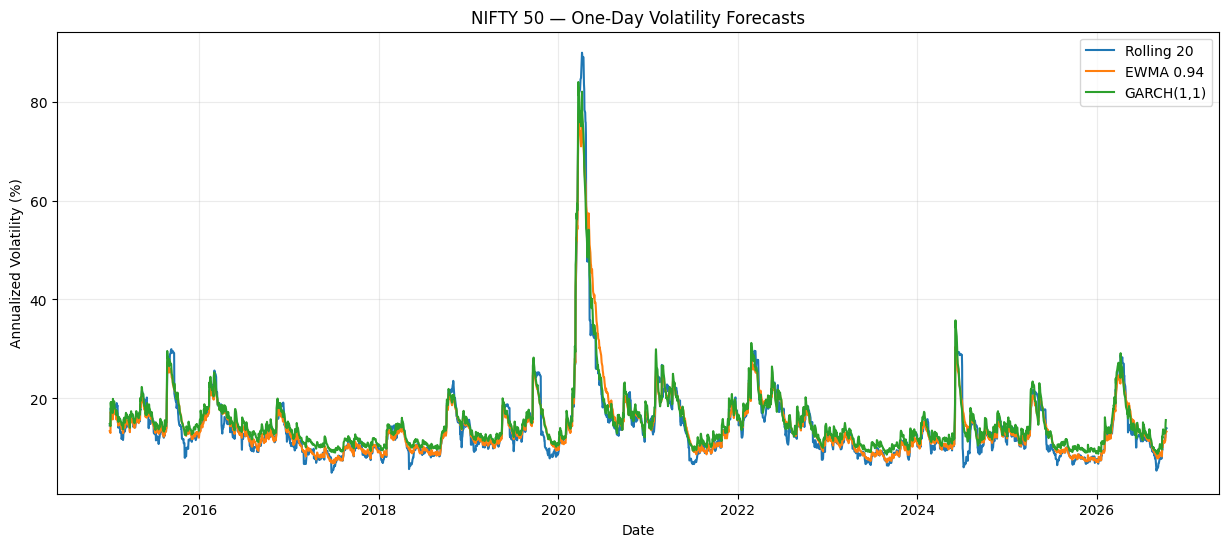

In [ ]:
comparison = vol_forecasts.loc[
    "2015-01-01":
]

plt.figure(figsize=(15, 6))

plt.plot(
    comparison.index,
    100 * comparison["Rolling20_Ann_Vol"],
    label="Rolling 20"
)

plt.plot(
    comparison.index,
    100 * comparison["EWMA94_Ann_Vol"],
    label="EWMA 0.94"
)

plt.plot(
    comparison.index,
    100 * comparison["GARCH11_Ann_Vol"],
    label="GARCH(1,1)"
)

plt.title(
    "NIFTY 50 — One-Day Volatility Forecasts"
)

plt.xlabel("Date")
plt.ylabel("Annualized Volatility (%)")

plt.legend()
plt.grid(alpha=0.25)

plt.show()

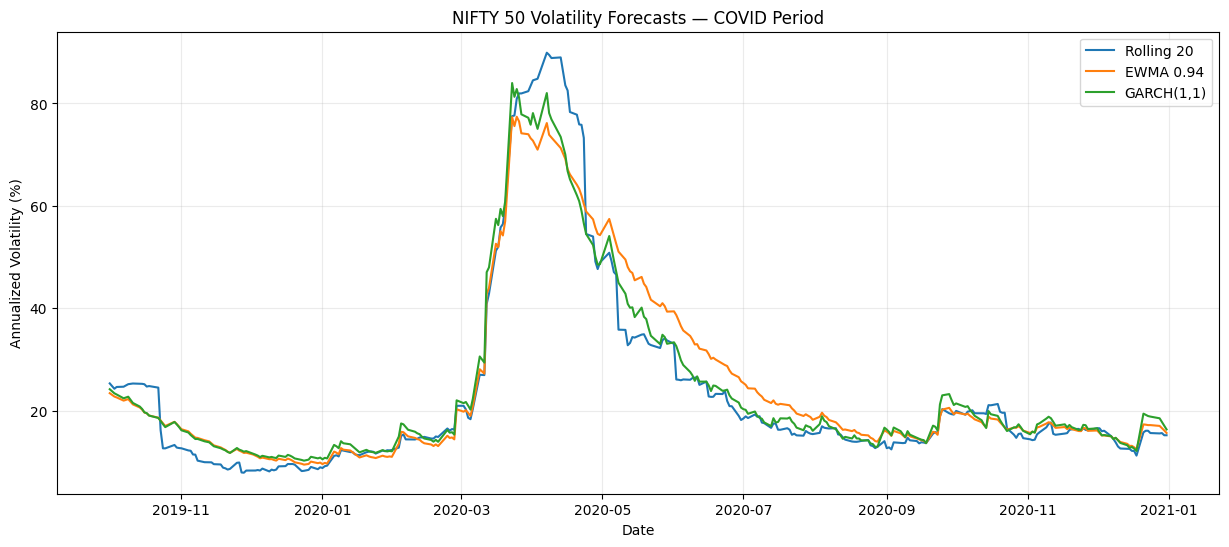

In [ ]:
covid_compare = comparison.loc[
    "2019-10-01":"2020-12-31"
]

plt.figure(figsize=(15, 6))

plt.plot(
    covid_compare.index,
    100 * covid_compare[
        "Rolling20_Ann_Vol"
    ],
    label="Rolling 20"
)

plt.plot(
    covid_compare.index,
    100 * covid_compare[
        "EWMA94_Ann_Vol"
    ],
    label="EWMA 0.94"
)

plt.plot(
    covid_compare.index,
    100 * covid_compare[
        "GARCH11_Ann_Vol"
    ],
    label="GARCH(1,1)"
)

plt.title(
    "NIFTY 50 Volatility Forecasts — COVID Period"
)

plt.ylabel("Annualized Volatility (%)")
plt.xlabel("Date")

plt.legend()
plt.grid(alpha=0.25)

plt.show()

In [ ]:
def forecast_vol_summary(series):
    x = series.dropna()

    return pd.Series({
        "Start": x.index.min().date(),
        "End": x.index.max().date(),
        "Observations": len(x),
        "Mean_Ann_Vol": x.mean(),
        "Median_Ann_Vol": x.median(),
        "Max_Ann_Vol": x.max(),
        "Max_Vol_Date": x.idxmax().date()
    })


garch_summary = forecast_vol_summary(
    garch11_vol_annual
)

display(
    garch_summary.to_frame("GARCH11")
)

,GARCH11
Start,2014-12-31
End,2026-10-09
Observations,2899
Mean_Ann_Vol,0.152567
Median_Ann_Vol,0.136316
Max_Ann_Vol,0.839788
Max_Vol_Date,2020-03-23


In [ ]:
persistence_summary = pd.Series({
    "Mean_alpha":
        garch_params["alpha"].mean(),

    "Mean_beta":
        garch_params["beta"].mean(),

    "Mean_alpha_plus_beta":
        garch_params[
            "alpha_plus_beta"
        ].mean(),

    "Median_alpha_plus_beta":
        garch_params[
            "alpha_plus_beta"
        ].median(),

    "Min_alpha_plus_beta":
        garch_params[
            "alpha_plus_beta"
        ].min(),

    "Max_alpha_plus_beta":
        garch_params[
            "alpha_plus_beta"
        ].max()
})

display(
    persistence_summary.to_frame("Value")
)

,Value
Mean_alpha,0.082305
Mean_beta,0.911559
Mean_alpha_plus_beta,0.993864
Median_alpha_plus_beta,0.993555
Min_alpha_plus_beta,0.991270
Max_alpha_plus_beta,0.997189


In [ ]:
vol_forecasts.to_csv(
    PROCESSED_DIR /
    "nifty50_all_volatility_forecasts.csv"
)

garch_params.to_csv(
    PROCESSED_DIR /
    "garch_monthly_parameter_history.csv"
)

print("Saved GARCH forecasts and parameter history.")

Saved GARCH forecasts and parameter history.


In [ ]:
vol_forecasts["Next_Day_Squared_Return"]

,Next_Day_Squared_Return
Date,
2007-09-17,0.000130
2007-09-18,0.001610
2007-09-19,0.000010
2007-09-20,0.000353
2007-09-21,0.000375
...,...
2026-10-06,0.000058
2026-10-07,0.000274
2026-10-08,0.000166


In [ ]:
# Target trading date corresponding to each forecast.
#
# Forecast stored at date t predicts variance for
# the NEXT available trading date.

vol_forecasts["Target_Date"] = (
    pd.Series(
        vol_forecasts.index,
        index=vol_forecasts.index
    )
    .shift(-1)
)

In [ ]:
display(
    vol_forecasts[
        [
            "Return",
            "Next_Day_Squared_Return",
            "Target_Date",
            "Rolling20_Var_Forecast",
            "EWMA94_Var_Forecast",
            "GARCH11_Var_Forecast"
        ]
    ].loc["2014-12-20":"2015-01-15"]
)

,Return,Next_Day_Squared_Return,Target_Date,Rolling20_Var_Forecast,EWMA94_Var_Forecast,GARCH11_Var_Forecast
Date,,,,,,
2014-12-22,0.011940,4.721370e-05,2014-12-23,0.000074,0.000076,NaN
2014-12-23,-0.006871,1.277139e-04,2014-12-24,0.000073,0.000075,NaN
2014-12-24,-0.011301,1.055541e-05,2014-12-26,0.000079,0.000078,NaN
2014-12-26,0.003249,3.074759e-05,2014-12-29,0.000080,0.000074,NaN
2014-12-29,0.005545,5.591589e-08,2014-12-30,0.000075,0.000071,NaN
2014-12-30,0.000236,1.737197e-05,2014-12-31,0.000074,0.000067,NaN
2014-12-31,0.004168,1.828145e-04,2015-01-02,0.000075,0.000064,0.000079
2015-01-02,0.013521,4.132697e-06,2015-01-05,0.000084,0.000071,0.000087
2015-01-05,-0.002033,9.255031e-04,2015-01-06,0.000083,0.000067,0.000082


In [ ]:
model_cols = [
    "Rolling20_Var_Forecast",
    "EWMA94_Var_Forecast",
    "GARCH11_Var_Forecast"
]

evaluation = (
    vol_forecasts[
        [
            "Target_Date",
            "Next_Day_Squared_Return"
        ] + model_cols
    ]
    .dropna()
    .copy()
)

In [ ]:
evaluation = evaluation.set_index(
    "Target_Date"
)

evaluation.index = pd.to_datetime(
    evaluation.index
)

evaluation.index.name = "Date"

In [ ]:
evaluation = evaluation.loc[
    "2015-01-01":
]

In [ ]:
print(
    "Evaluation start:",
    evaluation.index.min()
)

print(
    "Evaluation end:",
    evaluation.index.max()
)

print(
    "Number of OOS forecasts:",
    len(evaluation)
)

display(evaluation.head())

Evaluation start: 2015-01-02 00:00:00
Evaluation end: 2026-10-12 00:00:00
Number of OOS forecasts: 2899


,Next_Day_Squared_Return,Rolling20_Var_Forecast,EWMA94_Var_Forecast,GARCH11_Var_Forecast
Date,,,,
2015-01-02,0.000183,0.000075,0.000064,0.000079
2015-01-05,0.000004,0.000084,0.000071,0.000087
2015-01-06,0.000926,0.000083,0.000067,0.000082
2015-01-07,0.000010,0.000129,0.000119,0.000146
2015-01-08,0.000263,0.000123,0.000112,0.000137


In [ ]:
actual = evaluation[
    "Next_Day_Squared_Return"
]

for model in model_cols:

    evaluation[
        f"{model}_AE"
    ] = np.abs(
        actual - evaluation[model]
    )

In [ ]:
for model in model_cols:

    evaluation[
        f"{model}_SE"
    ] = (
        actual - evaluation[model]
    ) ** 2

In [ ]:
EPS = 1e-12

In [ ]:
for model in model_cols:

    predicted_var = (
        evaluation[model]
        .clip(lower=EPS)
    )

    evaluation[
        f"{model}_QLIKE"
    ] = (
        np.log(predicted_var)
        +
        actual / predicted_var
    )

In [ ]:
model_names = {
    "Rolling20_Var_Forecast":
        "Rolling20",

    "EWMA94_Var_Forecast":
        "EWMA94",

    "GARCH11_Var_Forecast":
        "GARCH11"
}

In [ ]:
results = []

for model_col, model_name in model_names.items():

    mae = evaluation[
        f"{model_col}_AE"
    ].mean()

    mse = evaluation[
        f"{model_col}_SE"
    ].mean()

    qlike = evaluation[
        f"{model_col}_QLIKE"
    ].mean()

    results.append({
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "QLIKE": qlike
    })


forecast_results = (
    pd.DataFrame(results)
    .set_index("Model")
)

In [ ]:
display(forecast_results)

,MAE,MSE,QLIKE
Model,,,
Rolling20,0.000117,2.180842e-07,-8.439148
EWMA94,0.000115,2.096577e-07,-8.458632
GARCH11,0.000117,2.059616e-07,-8.476741


In [ ]:
forecast_results_readable = (
    forecast_results.copy()
)

forecast_results_readable[
    "MAE_x1e4"
] = (
    forecast_results_readable["MAE"]
    * 1e4
)

forecast_results_readable[
    "MSE_x1e8"
] = (
    forecast_results_readable["MSE"]
    * 1e8
)

display(
    forecast_results_readable[
        [
            "MAE_x1e4",
            "MSE_x1e8",
            "QLIKE"
        ]
    ].sort_values("QLIKE")
)

,MAE_x1e4,MSE_x1e8,QLIKE
Model,,,
GARCH11,1.170058,20.596158,-8.476741
EWMA94,1.147267,20.965767,-8.458632
Rolling20,1.166655,21.808421,-8.439148


In [ ]:
rolling_qlike = (
    forecast_results
    .loc["Rolling20", "QLIKE"]
)

In [ ]:
qlike_relative = {}

rolling_daily_loss = evaluation[
    "Rolling20_Var_Forecast_QLIKE"
]

for model_col, model_name in model_names.items():

    model_loss = evaluation[
        f"{model_col}_QLIKE"
    ]

    qlike_relative[
        model_name
    ] = (
        model_loss -
        rolling_daily_loss
    ).mean()

In [ ]:
qlike_relative_table = (
    pd.Series(
        qlike_relative,
        name="Mean_QLIKE_Difference_vs_Rolling"
    )
    .to_frame()
)

display(qlike_relative_table)

,Mean_QLIKE_Difference_vs_Rolling
Rolling20,0.000000
EWMA94,-0.019484
GARCH11,-0.037594


In [ ]:
evaluation["Year"] = (
    evaluation.index.year
)

In [ ]:
yearly_qlike = pd.DataFrame(
    index=sorted(
        evaluation["Year"].unique()
    )
)

for model_col, model_name in model_names.items():

    yearly_qlike[
        model_name
    ] = (
        evaluation
        .groupby("Year")[
            f"{model_col}_QLIKE"
        ]
        .mean()
    )

In [ ]:
yearly_qlike["Winner"] = (
    yearly_qlike[
        [
            "Rolling20",
            "EWMA94",
            "GARCH11"
        ]
    ]
    .idxmin(axis=1)
)

In [ ]:
display(yearly_qlike)

,Rolling20,EWMA94,GARCH11,Winner
2015,-8.076880,-8.072325,-8.104040,GARCH11
2016,-8.279191,-8.297004,-8.310152,GARCH11
2017,-9.203242,-9.265293,-9.228151,EWMA94
2018,-8.653566,-8.689700,-8.707769,GARCH11
2019,-8.502493,-8.493470,-8.508776,GARCH11
2020,-7.377962,-7.326494,-7.411167,GARCH11
2021,-8.352292,-8.338364,-8.358919,GARCH11
2022,-8.058146,-8.091585,-8.097211,GARCH11
2023,-9.124166,-9.149548,-9.126649,EWMA94
2024,-8.303127,-8.416141,-8.471896,GARCH11


In [ ]:
completed_years = yearly_qlike.loc[
    yearly_qlike.index <= 2025
]

In [ ]:
year_wins = (
    completed_years[
        "Winner"
    ]
    .value_counts()
)

In [ ]:
print(
    "QLIKE calendar-year wins "
    "(2015-2025 only):"
)

display(
    year_wins.to_frame("Years_Won")
)

QLIKE calendar-year wins (2015-2025 only):


,Years_Won
Winner,
GARCH11,8
EWMA94,3


In [ ]:
covid_eval = evaluation.loc[
    "2020-01-01":"2020-12-31"
]

In [ ]:
daily_loss_columns = {
    "Rolling20":
        "Rolling20_Var_Forecast_QLIKE",

    "EWMA94":
        "EWMA94_Var_Forecast_QLIKE",

    "GARCH11":
        "GARCH11_Var_Forecast_QLIKE"
}

In [ ]:
daily_qlike = evaluation[
    list(
        daily_loss_columns.values()
    )
].rename(
    columns={
        v: k
        for k, v
        in daily_loss_columns.items()
    }
)

In [ ]:
daily_winner = (
    daily_qlike.idxmin(axis=1)
)

daily_win_share = (
    daily_winner
    .value_counts(normalize=True)
    .sort_values(ascending=False)
)

display(
    (
        100 * daily_win_share
    ).to_frame(
        "Daily_Win_Percent"
    )
)

,Daily_Win_Percent
Rolling20,42.842359
EWMA94,31.424629
GARCH11,25.733011


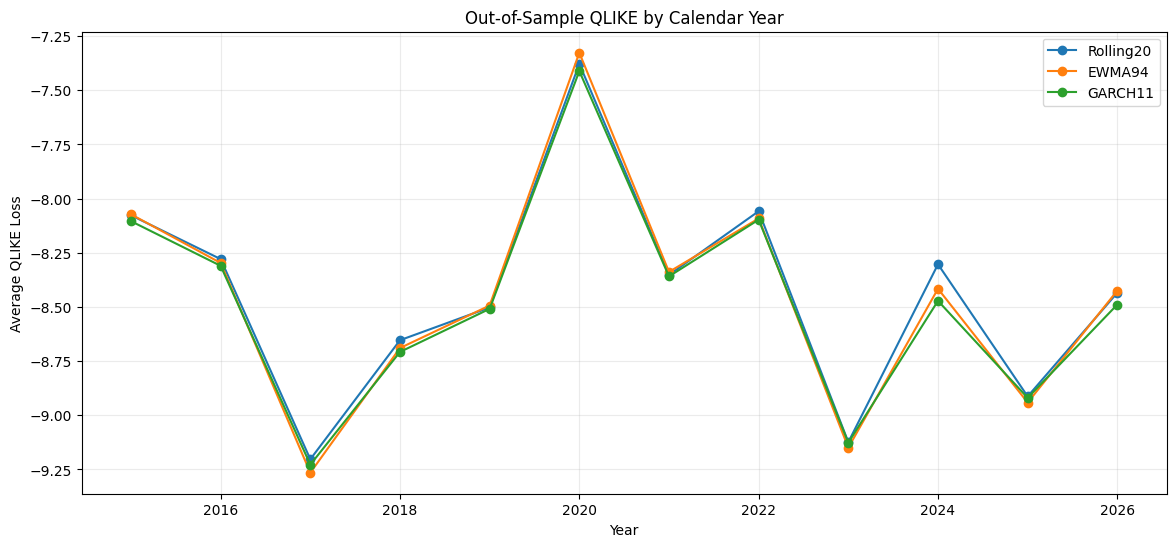

In [ ]:
yearly_qlike[
    [
        "Rolling20",
        "EWMA94",
        "GARCH11"
    ]
].plot(
    figsize=(14, 6),
    marker="o"
)

plt.title(
    "Out-of-Sample QLIKE by Calendar Year"
)

plt.xlabel("Year")
plt.ylabel("Average QLIKE Loss")

plt.grid(alpha=0.25)
plt.legend()

plt.show()

In [ ]:
forecast_results.to_csv(
    PROCESSED_DIR /
    "volatility_forecast_overall_results.csv"
)

yearly_qlike.to_csv(
    PROCESSED_DIR /
    "volatility_forecast_yearly_qlike.csv"
)

evaluation.to_csv(
    PROCESSED_DIR /
    "volatility_forecast_evaluation_daily.csv"
)

print("Stage 4 forecast evaluation saved.")

Stage 4 forecast evaluation saved.


STAGE 5

In [ ]:
evaluation["Realized_Log_Return"] = (
    nifty["Log_Return"]
    .reindex(evaluation.index)
)

In [ ]:
print(evaluation["Realized_Log_Return"].isna().sum())

display(
    evaluation[
        [
            "Realized_Log_Return",
            "Rolling20_Var_Forecast",
            "EWMA94_Var_Forecast",
            "GARCH11_Var_Forecast"
        ]
    ].head()
)

0


,Realized_Log_Return,Rolling20_Var_Forecast,EWMA94_Var_Forecast,GARCH11_Var_Forecast
Date,,,,
2015-01-02,0.013521,0.000075,0.000064,0.000079
2015-01-05,-0.002033,0.000084,0.000071,0.000087
2015-01-06,-0.030422,0.000083,0.000067,0.000082
2015-01-07,-0.003112,0.000129,0.000119,0.000146
2015-01-08,0.016221,0.000123,0.000112,0.000137


In [ ]:
for model_col, model_name in model_names.items():

    evaluation[
        f"{model_name}_Sigma"
    ] = np.sqrt(
        evaluation[model_col]
    )

In [ ]:
from scipy.stats import norm

Z_95 = norm.ppf(0.95)
Z_99 = norm.ppf(0.99)

print(f"95% z-value: {Z_95:.6f}")
print(f"99% z-value: {Z_99:.6f}")

95% z-value: 1.644854
99% z-value: 2.326348


In [ ]:
confidence_levels = {
    0.95: Z_95,
    0.99: Z_99
}

for model_name in model_names.values():

    sigma = evaluation[
        f"{model_name}_Sigma"
    ]

    for confidence, z in confidence_levels.items():

        label = int(confidence * 100)

        evaluation[
            f"{model_name}_VaR{label}"
        ] = z * sigma

In [ ]:
for model_name in model_names.values():

    for confidence in confidence_levels:

        label = int(confidence * 100)

        evaluation[
            f"{model_name}_Violation{label}"
        ] = (
            evaluation["Realized_Log_Return"]
            <
            -evaluation[
                f"{model_name}_VaR{label}"
            ]
        )

In [ ]:
var_coverage_results = []

T = len(evaluation)

for model_name in model_names.values():

    for confidence in confidence_levels:

        label = int(confidence * 100)

        violation_col = (
            f"{model_name}_Violation{label}"
        )

        x = int(
            evaluation[
                violation_col
            ].sum()
        )

        observed_rate = x / T

        expected_rate = (
            1 - confidence
        )

        expected_count = (
            expected_rate * T
        )

        var_coverage_results.append({
            "Model": model_name,
            "VaR_Level": f"{label}%",
            "Observations": T,
            "Expected_Rate": expected_rate,
            "Observed_Rate": observed_rate,
            "Expected_Exceptions": expected_count,
            "Observed_Exceptions": x,
            "Obs_to_Expected": (
                x / expected_count
            )
        })


var_coverage = pd.DataFrame(
    var_coverage_results
)

display(var_coverage)

,Model,VaR_Level,Observations,Expected_Rate,Observed_Rate,Expected_Exceptions,Observed_Exceptions,Obs_to_Expected
0,Rolling20,95%,2899,0.05,0.065195,144.95,189,1.303898
1,Rolling20,99%,2899,0.01,0.023111,28.99,67,2.311142
2,EWMA94,95%,2899,0.05,0.059331,144.95,172,1.186616
3,EWMA94,99%,2899,0.01,0.019662,28.99,57,1.966195
4,GARCH11,95%,2899,0.05,0.045533,144.95,132,0.910659
5,GARCH11,99%,2899,0.01,0.015523,28.99,45,1.552259


In [ ]:
from scipy.stats import chi2
from scipy.special import xlogy


def kupiec_test(
    violations,
    expected_violation_rate
):
    """
    Kupiec unconditional coverage test.

    H0:
        observed violation probability equals
        expected violation probability.

    Parameters
    ----------
    violations:
        Boolean / 0-1 sequence.

    expected_violation_rate:
        Example:
        0.05 for 95% VaR
        0.01 for 99% VaR
    """

    violations = pd.Series(
        violations
    ).dropna().astype(int)

    n = len(violations)
    x = int(violations.sum())

    if n == 0:
        raise ValueError(
            "No observations supplied."
        )

    p0 = expected_violation_rate
    p_hat = x / n

    # Null likelihood
    logL_null = (
        xlogy(x, p0)
        +
        xlogy(
            n - x,
            1 - p0
        )
    )

    # Unrestricted likelihood
    #
    # xlogy safely handles cases such as
    # 0 * log(0).
    logL_alt = (
        xlogy(x, p_hat)
        +
        xlogy(
            n - x,
            1 - p_hat
        )
    )

    lr_uc = (
        -2 *
        (logL_null - logL_alt)
    )

    p_value = (
        1 -
        chi2.cdf(
            lr_uc,
            df=1
        )
    )

    return {
        "Observations": n,
        "Exceptions": x,
        "Expected_Rate": p0,
        "Observed_Rate": p_hat,
        "LR_UC": lr_uc,
        "p_value": p_value,
        "Reject_5pct": p_value < 0.05
    }

In [ ]:
kupiec_results = []

for model_name in model_names.values():

    for confidence in confidence_levels:

        label = int(
            confidence * 100
        )

        violation_col = (
            f"{model_name}_Violation{label}"
        )

        expected_violation_rate = (
            1 - confidence
        )

        result = kupiec_test(
            evaluation[
                violation_col
            ],
            expected_violation_rate
        )

        result["Model"] = model_name
        result["VaR_Level"] = (
            f"{label}%"
        )

        kupiec_results.append(
            result
        )


kupiec_table = pd.DataFrame(
    kupiec_results
)

kupiec_table = kupiec_table[
    [
        "Model",
        "VaR_Level",
        "Observations",
        "Exceptions",
        "Expected_Rate",
        "Observed_Rate",
        "LR_UC",
        "p_value",
        "Reject_5pct"
    ]
]

display(kupiec_table)

,Model,VaR_Level,Observations,Exceptions,Expected_Rate,Observed_Rate,LR_UC,p_value,Reject_5pct
0,Rolling20,95%,2899,189,0.05,0.065195,12.913734,3.261799e-04,True
1,Rolling20,99%,2899,67,0.01,0.023111,36.743021,1.347722e-09,True
2,EWMA94,95%,2899,172,0.05,0.059331,5.026890,2.495667e-02,True
3,EWMA94,99%,2899,57,0.01,0.019662,21.329696,3.866947e-06,True
4,GARCH11,95%,2899,132,0.05,0.045533,1.253848,2.628189e-01,False
5,GARCH11,99%,2899,45,0.01,0.015523,7.643516,5.697676e-03,True


In [ ]:
yearly_var_rows = []

for year, group in evaluation.groupby(
    evaluation.index.year
):

    for model_name in model_names.values():

        for confidence in confidence_levels:

            label = int(
                confidence * 100
            )

            violation_col = (
                f"{model_name}_Violation{label}"
            )

            yearly_var_rows.append({
                "Year": year,
                "Model": model_name,
                "VaR_Level": f"{label}%",
                "Days": len(group),
                "Exceptions": int(
                    group[
                        violation_col
                    ].sum()
                )
            })


yearly_var = pd.DataFrame(
    yearly_var_rows
)

In [ ]:
yearly_var_99 = (
    yearly_var[
        yearly_var["VaR_Level"]
        == "99%"
    ]
    .pivot(
        index="Year",
        columns="Model",
        values="Exceptions"
    )
)

display(yearly_var_99)

Model,EWMA94,GARCH11,Rolling20
Year,,,
2015,5,4,7
2016,7,4,8
2017,2,1,3
2018,4,3,6
2019,1,1,1
2020,13,13,11
2021,5,5,6
2022,4,4,5
2023,3,0,3


In [ ]:
yearly_var_95 = (
    yearly_var[
        yearly_var["VaR_Level"]
        == "95%"
    ]
    .pivot(
        index="Year",
        columns="Model",
        values="Exceptions"
    )
)

display(yearly_var_95)

Model,EWMA94,GARCH11,Rolling20
Year,,,
2015,16,12,17
2016,17,11,16
2017,13,5,16
2018,15,12,17
2019,9,7,11
2020,17,17,19
2021,11,9,11
2022,15,15,17
2023,12,10,12


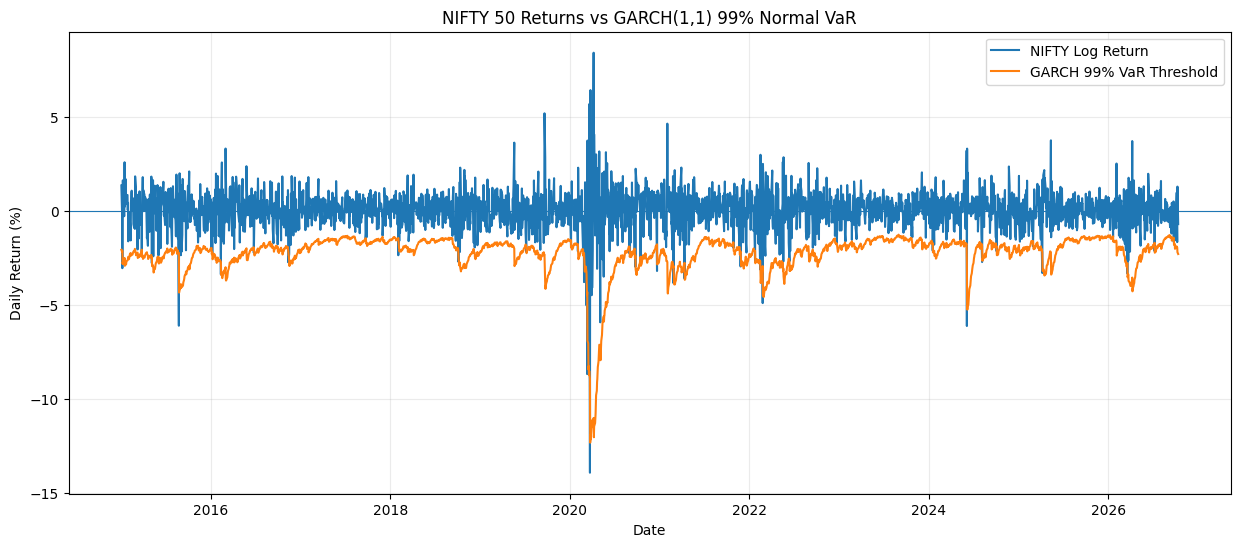

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(
    evaluation.index,
    100 * evaluation[
        "Realized_Log_Return"
    ],
    label="NIFTY Log Return"
)

plt.plot(
    evaluation.index,
    -100 * evaluation[
        "GARCH11_VaR99"
    ],
    label="GARCH 99% VaR Threshold"
)

plt.axhline(
    0,
    linewidth=0.8
)

plt.title(
    "NIFTY 50 Returns vs GARCH(1,1) 99% Normal VaR"
)

plt.xlabel("Date")
plt.ylabel("Daily Return (%)")

plt.legend()
plt.grid(alpha=0.25)

plt.show()

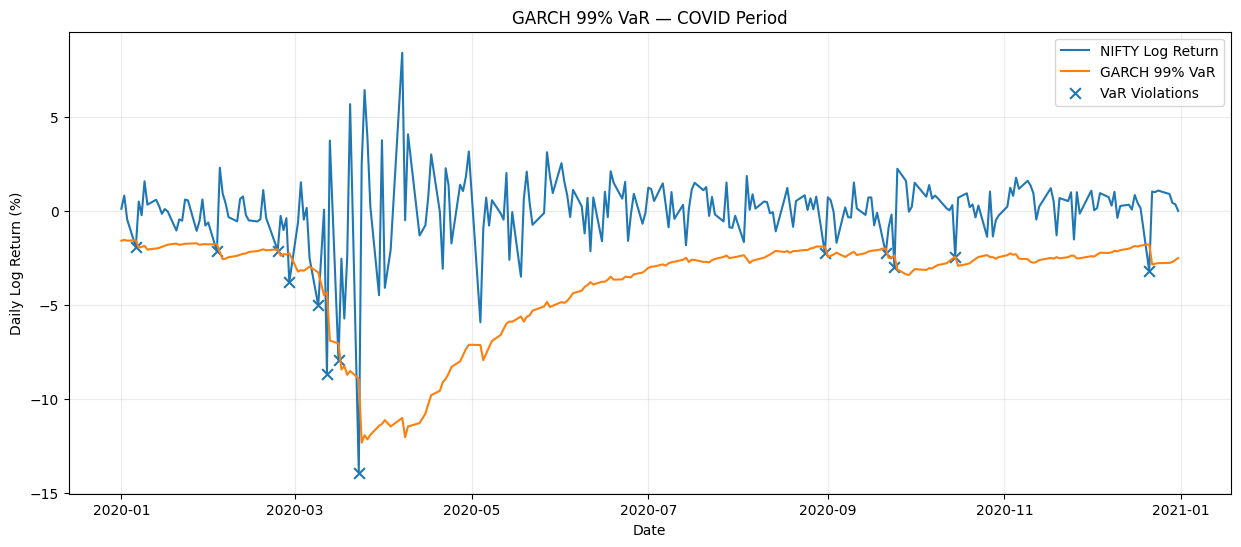

In [ ]:
covid_var = evaluation.loc[
    "2020-01-01":"2020-12-31"
]

plt.figure(figsize=(15, 6))

plt.plot(
    covid_var.index,
    100 * covid_var[
        "Realized_Log_Return"
    ],
    label="NIFTY Log Return"
)

plt.plot(
    covid_var.index,
    -100 * covid_var[
        "GARCH11_VaR99"
    ],
    label="GARCH 99% VaR"
)

violations = covid_var[
    covid_var[
        "GARCH11_Violation99"
    ]
]

plt.scatter(
    violations.index,
    100 * violations[
        "Realized_Log_Return"
    ],
    marker="x",
    s=60,
    label="VaR Violations"
)

plt.title(
    "GARCH 99% VaR — COVID Period"
)

plt.xlabel("Date")
plt.ylabel("Daily Log Return (%)")

plt.legend()
plt.grid(alpha=0.25)

plt.show()

In [ ]:
var_coverage.to_csv(
    PROCESSED_DIR /
    "var_coverage_results.csv",
    index=False
)

kupiec_table.to_csv(
    PROCESSED_DIR /
    "kupiec_test_results.csv",
    index=False
)

yearly_var.to_csv(
    PROCESSED_DIR /
    "yearly_var_exceptions.csv",
    index=False
)

evaluation.to_csv(
    PROCESSED_DIR /
    "evaluation_with_var.csv"
)

print("Stage 5 VaR results saved.")

Stage 5 VaR results saved.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TRADING_DAYS = 252

VOL_TARGET = 0.12
BASE_COST_BPS = 5

MA_WINDOW = 200

In [ ]:
strategy_data = pd.DataFrame(
    index=nifty.index
)

strategy_data["Price"] = nifty["Price"]

strategy_data["Equity_Return"] = (
    nifty["Return"]
)

strategy_data["RF_Return"] = (
    nifty["RF_Return"]
)

strategy_data["EWMA_Ann_Vol"] = (
    ewma94_vol_annual
)

strategy_data["MA200"] = (
    strategy_data["Price"]
    .rolling(MA_WINDOW)
    .mean()
)

In [ ]:
strategy_data["Trend_Signal"] = (
    strategy_data["Price"]
    >
    strategy_data["MA200"]
).astype(float)

In [ ]:
raw_vol_weight = (
    VOL_TARGET /
    strategy_data["EWMA_Ann_Vol"]
)

strategy_data[
    "Vol_Target_Raw"
] = raw_vol_weight.clip(
    lower=0,
    upper=1
)

In [ ]:
display(
    strategy_data[
        "Vol_Target_Raw"
    ].describe()
)

,Vol_Target_Raw
count,4658.000000
mean,0.771053
std,0.232475
min,0.152807
25%,0.614650
50%,0.826204
75%,1.000000
max,1.000000


In [ ]:
week_id = pd.Series(
    strategy_data.index.to_period("W-FRI"),
    index=strategy_data.index
)

strategy_data["Is_Week_End"] = (
    week_id != week_id.shift(-1)
)

In [ ]:
display(
    strategy_data[
        ["Price", "Is_Week_End"]
    ].head(30)
)

,Price,Is_Week_End
Date,,
2007-09-17,4494.649902,False
2007-09-18,4546.200195,False
2007-09-19,4732.350098,False
2007-09-20,4747.549805,False
2007-09-21,4837.549805,True
2007-09-24,4932.200195,False
2007-09-25,4938.850098,False
2007-09-26,4940.500000,False
2007-09-27,5000.549805,False


In [ ]:
def weekly_rebalanced_target(
    raw_target,
    week_end_mask
):
    """
    Target can change only on the final trading day
    of each trading week.

    Between rebalance dates, the latest target
    is carried forward.
    """

    raw_target = raw_target.copy()

    scheduled = raw_target.where(
        week_end_mask
    )

    held_target = scheduled.ffill()

    return held_target

In [ ]:
strategy_data[
    "Vol_Target"
] = weekly_rebalanced_target(
    strategy_data["Vol_Target_Raw"],
    strategy_data["Is_Week_End"]
)

In [ ]:
strategy_data[
    "TrendVol_Target_Raw"
] = (
    strategy_data["Trend_Signal"]
    *
    strategy_data["Vol_Target_Raw"]
)

In [ ]:
strategy_data[
    "TrendVol_Target"
] = weekly_rebalanced_target(
    strategy_data[
        "TrendVol_Target_Raw"
    ],
    strategy_data[
        "Is_Week_End"
    ]
)

In [ ]:
strategy_data[
    "Trend_Target"
] = strategy_data[
    "Trend_Signal"
]

In [ ]:
strategy_data[
    "BuyHold_Target"
] = 1.0

In [ ]:
def run_backtest(
    equity_return,
    rf_return,
    target_weight,
    cost_bps=5,
    execution_lag=1,
    initial_equity_weight=0.0
):
    """
    Backtest a long-only equity/cash strategy.

    target_weight[t]:
        Desired equity weight decided using information
        available through the close of day t.

    execution_lag=1:
        target decided at t is applied to the return
        beginning after t.

    Portfolio return:

        w_t * R_equity,t
        + (1 - w_t) * R_f,t
        - cost

    Transaction cost:

        c * |w_t - w_{t-1}|
    """

    df = pd.DataFrame({
        "Equity_Return": equity_return,
        "RF_Return": rf_return,
        "Target_Weight": target_weight
    }).copy()

    # Apply decision only after the requested lag.
    df["Weight"] = (
        df["Target_Weight"]
        .shift(execution_lag)
    )

    df = df.dropna(
        subset=[
            "Equity_Return",
            "RF_Return",
            "Weight"
        ]
    )

    if df.empty:
        raise ValueError(
            "Backtest has no valid observations."
        )

    # Previous actual exposure.
    previous_weight = (
        df["Weight"]
        .shift(1)
    )

    # Starting assumption: we begin in cash.
    previous_weight.iloc[0] = (
        initial_equity_weight
    )

    df["Turnover"] = (
        df["Weight"]
        -
        previous_weight
    ).abs()

    cost_rate = (
        cost_bps / 10_000
    )

    df["Transaction_Cost"] = (
        cost_rate *
        df["Turnover"]
    )

    df["Portfolio_Return"] = (
        df["Weight"]
        * df["Equity_Return"]
        +
        (
            1 - df["Weight"]
        )
        * df["RF_Return"]
        -
        df["Transaction_Cost"]
    )

    df["Excess_Return"] = (
        df["Portfolio_Return"]
        -
        df["RF_Return"]
    )

    df["Wealth"] = (
        1 + df["Portfolio_Return"]
    ).cumprod()

    df["Peak_Wealth"] = (
        df["Wealth"]
        .cummax()
    )

    df["Drawdown"] = (
        df["Wealth"]
        /
        df["Peak_Wealth"]
        - 1
    )

    return df

In [ ]:
test_bh = run_backtest(
    equity_return=strategy_data[
        "Equity_Return"
    ],
    rf_return=strategy_data[
        "RF_Return"
    ],
    target_weight=strategy_data[
        "BuyHold_Target"
    ],
    cost_bps=0,
    execution_lag=1,
    initial_equity_weight=1.0
)

In [ ]:
max_difference = np.max(
    np.abs(
        test_bh["Portfolio_Return"]
        -
        test_bh["Equity_Return"]
    )
)

print(
    "Max Buy-and-Hold return difference:",
    max_difference
)

assert max_difference < 1e-12

Max Buy-and-Hold return difference: 0.0


In [ ]:
constant_weight = pd.Series(
    0.60,
    index=strategy_data.index
)

test_constant = run_backtest(
    equity_return=strategy_data[
        "Equity_Return"
    ],
    rf_return=strategy_data[
        "RF_Return"
    ],
    target_weight=constant_weight,
    cost_bps=0,
    execution_lag=1,
    initial_equity_weight=0.60
)

In [ ]:
constant_weight = pd.Series(
    0.60,
    index=strategy_data.index
)

test_constant = run_backtest(
    equity_return=strategy_data[
        "Equity_Return"
    ],
    rf_return=strategy_data[
        "RF_Return"
    ],
    target_weight=constant_weight,
    cost_bps=0,
    execution_lag=1,
    initial_equity_weight=0.60
)

In [ ]:
manual_return = (
    0.60
    * test_constant[
        "Equity_Return"
    ]
    +
    0.40
    * test_constant[
        "RF_Return"
    ]
)

In [ ]:
max_difference = np.max(
    np.abs(
        test_constant[
            "Portfolio_Return"
        ]
        -
        manual_return
    )
)

print(
    "Max constant-weight difference:",
    max_difference
)

assert max_difference < 1e-12

Max constant-weight difference: 0.0


In [ ]:
cheating_target = (
    strategy_data[
        "Equity_Return"
    ]
    .shift(-1)
    > 0
).astype(float)

In [ ]:
cheat_bt = run_backtest(
    equity_return=strategy_data[
        "Equity_Return"
    ],
    rf_return=strategy_data[
        "RF_Return"
    ],
    target_weight=cheating_target,
    cost_bps=0,
    execution_lag=1
)

In [ ]:
legal_previous_return_target = (
    strategy_data[
        "Equity_Return"
    ]
    > 0
).astype(float)

In [ ]:
legal_bt = run_backtest(
    equity_return=strategy_data[
        "Equity_Return"
    ],
    rf_return=strategy_data[
        "RF_Return"
    ],
    target_weight=legal_previous_return_target,
    cost_bps=0,
    execution_lag=1
)

In [ ]:
def simple_sharpe(
    excess_returns
):
    x = excess_returns.dropna()

    return (
        np.sqrt(252)
        *
        x.mean()
        /
        x.std()
    )

In [ ]:
print(
    "CHEATING Sharpe:",
    simple_sharpe(
        cheat_bt[
            "Excess_Return"
        ]
    )
)

print(
    "Lagged/legal Sharpe:",
    simple_sharpe(
        legal_bt[
            "Excess_Return"
        ]
    )
)

CHEATING Sharpe: 8.641155939775789
Lagged/legal Sharpe: 0.643112276372385


In [143]:
required = strategy_data[
    [
        "Equity_Return",
        "RF_Return",
        "Trend_Target",
        "Vol_Target",
        "TrendVol_Target"
    ]
].dropna()

In [144]:
print(
    "Common strategy start:",
    required.index.min()
)

print(
    "Common strategy end:",
    required.index.max()
)

print(
    "Trading days:",
    len(required)
)

Common strategy start: 2007-10-19 00:00:00
Common strategy end: 2026-10-12 00:00:00
Trading days: 4655


In [145]:
common_index = required.index

sd = strategy_data.loc[
    common_index
].copy()

In [146]:
bt_buyhold = run_backtest(
    equity_return=sd[
        "Equity_Return"
    ],
    rf_return=sd[
        "RF_Return"
    ],
    target_weight=sd[
        "BuyHold_Target"
    ],
    cost_bps=BASE_COST_BPS,
    execution_lag=1,
    initial_equity_weight=0.0
)

In [147]:
bt_trend = run_backtest(
    equity_return=sd[
        "Equity_Return"
    ],
    rf_return=sd[
        "RF_Return"
    ],
    target_weight=sd[
        "Trend_Target"
    ],
    cost_bps=BASE_COST_BPS,
    execution_lag=1,
    initial_equity_weight=0.0
)

In [148]:
bt_vol = run_backtest(
    equity_return=sd[
        "Equity_Return"
    ],
    rf_return=sd[
        "RF_Return"
    ],
    target_weight=sd[
        "Vol_Target"
    ],
    cost_bps=BASE_COST_BPS,
    execution_lag=1,
    initial_equity_weight=0.0
)

In [149]:
bt_trendvol = run_backtest(
    equity_return=sd[
        "Equity_Return"
    ],
    rf_return=sd[
        "RF_Return"
    ],
    target_weight=sd[
        "TrendVol_Target"
    ],
    cost_bps=BASE_COST_BPS,
    execution_lag=1,
    initial_equity_weight=0.0
)

In [150]:
average_vol_exposure = (
    bt_vol["Weight"].mean()
)

print(
    f"Average vol-managed equity exposure: "
    f"{average_vol_exposure:.2%}"
)

Average vol-managed equity exposure: 77.16%


In [151]:
constant_mix_target = pd.Series(
    average_vol_exposure,
    index=sd.index
)

In [152]:
bt_constant = run_backtest(
    equity_return=sd[
        "Equity_Return"
    ],
    rf_return=sd[
        "RF_Return"
    ],
    target_weight=constant_mix_target,
    cost_bps=BASE_COST_BPS,
    execution_lag=1,
    initial_equity_weight=0.0
)

In [153]:
def performance_metrics(
    backtest,
    name
):
    r = (
        backtest[
            "Portfolio_Return"
        ]
        .dropna()
    )

    excess = (
        backtest[
            "Excess_Return"
        ]
        .reindex(r.index)
    )

    wealth = (
        backtest[
            "Wealth"
        ]
        .reindex(r.index)
    )

    drawdown = (
        backtest[
            "Drawdown"
        ]
        .reindex(r.index)
    )

    n = len(r)

    years = (
        n / TRADING_DAYS
    )

    final_wealth = (
        wealth.iloc[-1]
    )

    cagr = (
        final_wealth
        ** (1 / years)
        - 1
    )

    annual_return = (
        r.mean()
        * TRADING_DAYS
    )

    annual_vol = (
        r.std()
        * np.sqrt(TRADING_DAYS)
    )

    sharpe = (
        excess.mean()
        /
        excess.std()
        *
        np.sqrt(TRADING_DAYS)
    )

    max_drawdown = (
        drawdown.min()
    )

    total_turnover = (
        backtest[
            "Turnover"
        ].sum()
    )

    annual_turnover = (
        total_turnover /
        years
    )

    avg_exposure = (
        backtest[
            "Weight"
        ].mean()
    )

    return {
        "Strategy": name,
        "CAGR": cagr,
        "Annual_Return": annual_return,
        "Annual_Vol": annual_vol,
        "Sharpe": sharpe,
        "Max_Drawdown": max_drawdown,
        "Final_Wealth": final_wealth,
        "Average_Exposure": avg_exposure,
        "Annual_Turnover": annual_turnover
    }

In [154]:
backtests = {
    "Buy & Hold":
        bt_buyhold,

    "MA200 Trend":
        bt_trend,

    "EWMA Vol Managed":
        bt_vol,

    "MA200 + EWMA Vol":
        bt_trendvol,

    "Exposure-Matched Mix":
        bt_constant
}

In [155]:
performance_rows = []

for name, bt in backtests.items():

    performance_rows.append(
        performance_metrics(
            bt,
            name
        )
    )


performance_table = (
    pd.DataFrame(
        performance_rows
    )
    .set_index("Strategy")
)

display(
    performance_table
)

,CAGR,Annual_Return,Annual_Vol,Sharpe,Max_Drawdown,Final_Wealth,Average_Exposure,Annual_Turnover
Strategy,,,,,,,,
Buy & Hold,0.081989,0.099643,0.204051,0.202730,-0.598559,4.285871,1.000000,0.054147
MA200 Trend,0.081485,0.086285,0.126650,0.221157,-0.200412,4.249135,0.686076,7.797164
EWMA Vol Managed,0.072838,0.077559,0.120299,0.160297,-0.246092,3.663663,0.771644,2.109992
MA200 + EWMA Vol,0.073775,0.075753,0.095516,0.182978,-0.157380,3.723168,0.579877,4.152566
Exposure-Matched Mix,0.080893,0.090196,0.157455,0.202730,-0.493669,4.206404,0.771644,0.041782


In [156]:
readable = (
    performance_table.copy()
)

for col in [
    "CAGR",
    "Annual_Return",
    "Annual_Vol",
    "Max_Drawdown",
    "Average_Exposure",
    "Annual_Turnover"
]:
    readable[col] = (
        100 * readable[col]
    )

display(
    readable[
        [
            "CAGR",
            "Annual_Vol",
            "Sharpe",
            "Max_Drawdown",
            "Average_Exposure",
            "Annual_Turnover",
            "Final_Wealth"
        ]
    ].round(3)
)

,CAGR,Annual_Vol,Sharpe,Max_Drawdown,Average_Exposure,Annual_Turnover,Final_Wealth
Strategy,,,,,,,
Buy & Hold,8.199,20.405,0.203,-59.856,100.000,5.415,4.286
MA200 Trend,8.149,12.665,0.221,-20.041,68.608,779.716,4.249
EWMA Vol Managed,7.284,12.030,0.160,-24.609,77.164,210.999,3.664
MA200 + EWMA Vol,7.377,9.552,0.183,-15.738,57.988,415.257,3.723
Exposure-Matched Mix,8.089,15.745,0.203,-49.367,77.164,4.178,4.206


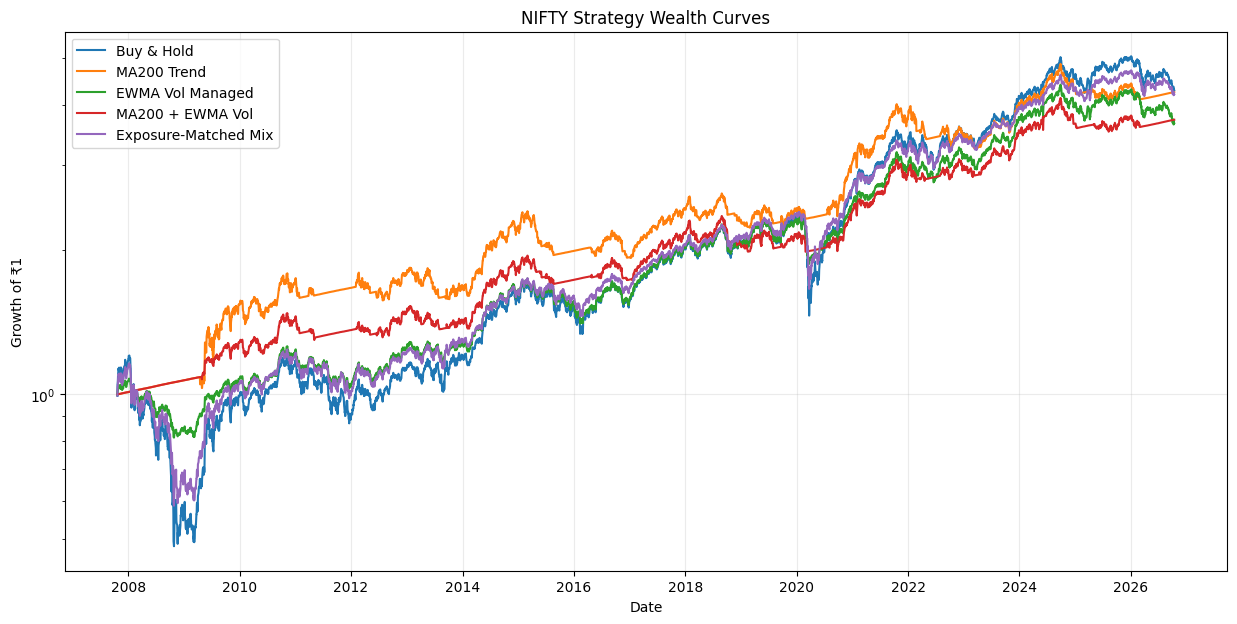

In [157]:
plt.figure(
    figsize=(15, 7)
)

for name, bt in backtests.items():

    plt.plot(
        bt.index,
        bt["Wealth"],
        label=name
    )

plt.title(
    "NIFTY Strategy Wealth Curves"
)

plt.xlabel("Date")
plt.ylabel(
    "Growth of ₹1"
)

plt.yscale("log")

plt.grid(
    alpha=0.25
)

plt.legend()

plt.show()

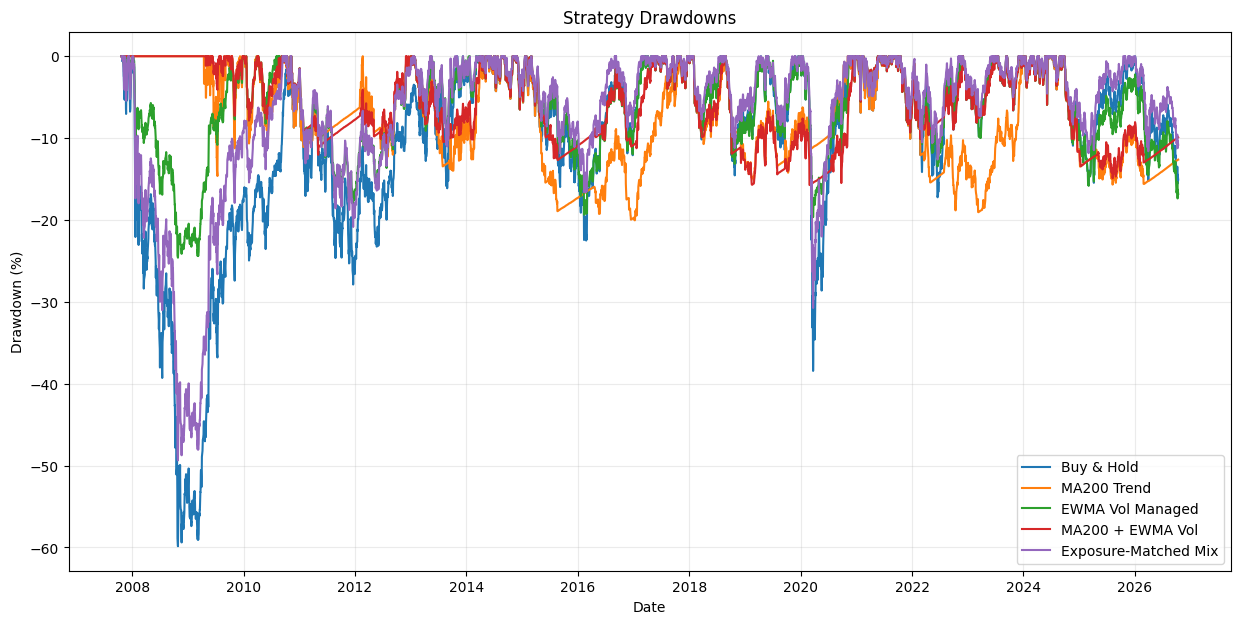

In [158]:
plt.figure(
    figsize=(15, 7)
)

for name, bt in backtests.items():

    plt.plot(
        bt.index,
        100 * bt["Drawdown"],
        label=name
    )

plt.title(
    "Strategy Drawdowns"
)

plt.xlabel("Date")
plt.ylabel(
    "Drawdown (%)"
)

plt.grid(
    alpha=0.25
)

plt.legend()

plt.show()

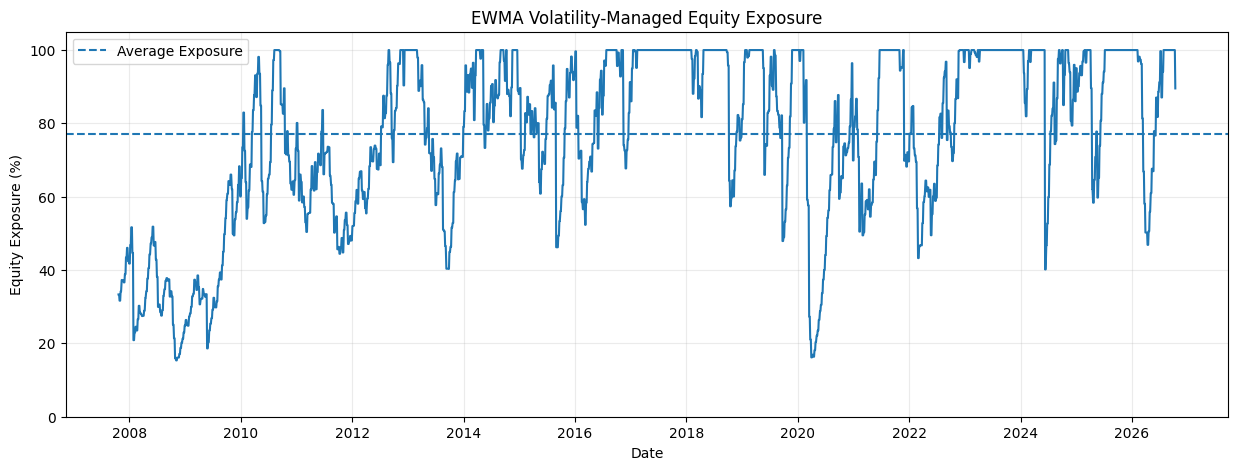

In [159]:
plt.figure(
    figsize=(15, 5)
)

plt.plot(
    bt_vol.index,
    100 * bt_vol[
        "Weight"
    ]
)

plt.axhline(
    100 * average_vol_exposure,
    linestyle="--",
    label="Average Exposure"
)

plt.title(
    "EWMA Volatility-Managed Equity Exposure"
)

plt.xlabel("Date")
plt.ylabel(
    "Equity Exposure (%)"
)

plt.ylim(
    0,
    105
)

plt.grid(
    alpha=0.25
)

plt.legend()

plt.show()

In [160]:
display(
    bt_vol.loc[
        "2008-08-01":"2009-03-31",
        [
            "Weight",
            "Equity_Return",
            "Portfolio_Return",
            "Drawdown"
        ]
    ].head(50)
)

,Weight,Equity_Return,Portfolio_Return,Drawdown
Date,,,,
2008-08-01,0.275673,0.018602,0.005295,-0.130398
2008-08-04,0.290996,-0.004124,-0.001044,-0.131305
2008-08-05,0.290996,0.024458,0.007281,-0.124980
2008-08-06,0.290996,0.003265,0.001114,-0.124005
2008-08-07,0.290996,0.001395,0.000570,-0.123506
2008-08-08,0.290996,0.001249,0.000527,-0.123044
2008-08-11,0.329627,0.020068,0.006751,-0.117124
2008-08-12,0.329627,-0.014750,-0.004707,-0.121279
2008-08-13,0.329627,-0.005096,-0.001525,-0.122619


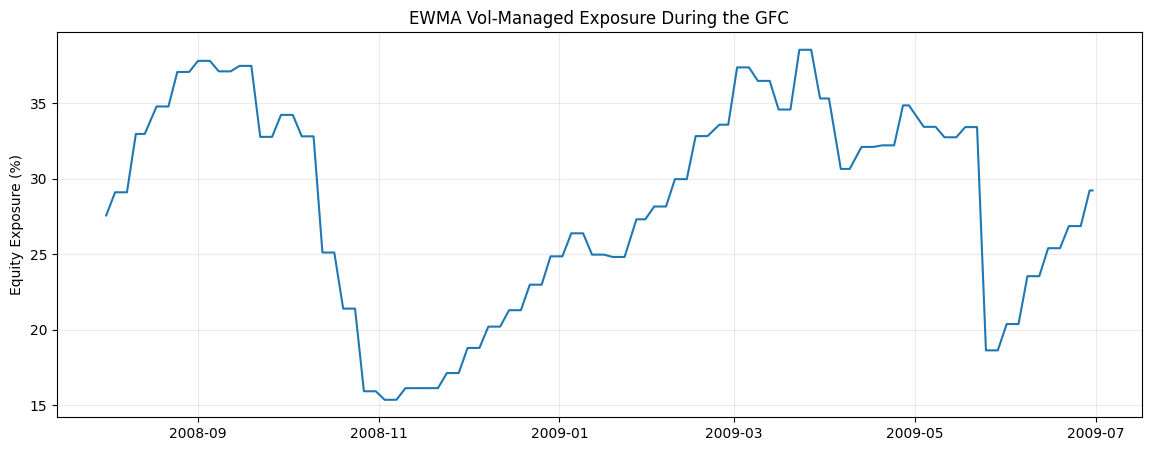

In [161]:
gfc = bt_vol.loc[
    "2008-08-01":"2009-06-30"
]

plt.figure(
    figsize=(14, 5)
)

plt.plot(
    gfc.index,
    100 * gfc["Weight"]
)

plt.title(
    "EWMA Vol-Managed Exposure During the GFC"
)

plt.ylabel(
    "Equity Exposure (%)"
)

plt.grid(
    alpha=0.25
)

plt.show()

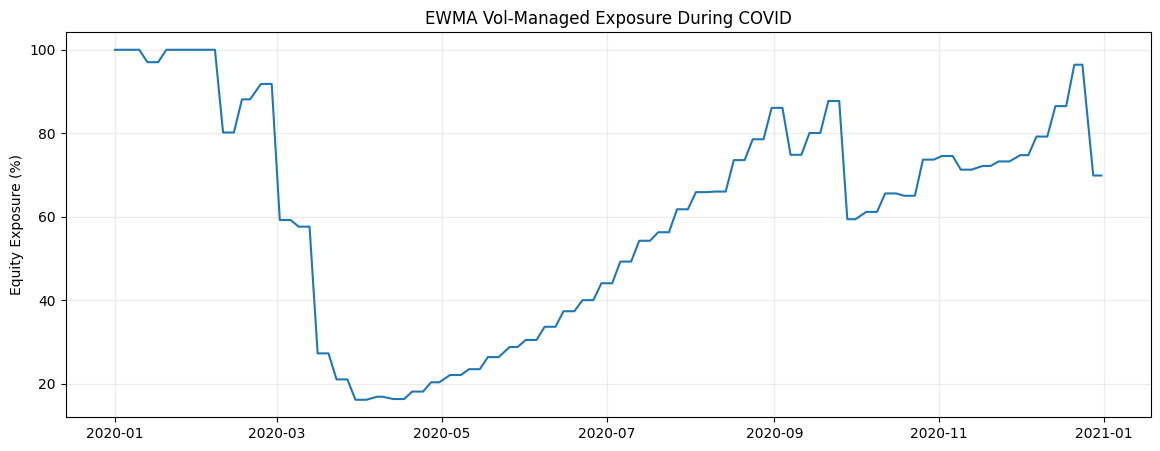

In [162]:
covid = bt_vol.loc[
    "2020-01-01":"2020-12-31"
]

plt.figure(
    figsize=(14, 5)
)

plt.plot(
    covid.index,
    100 * covid["Weight"]
)

plt.title(
    "EWMA Vol-Managed Exposure During COVID"
)

plt.ylabel(
    "Equity Exposure (%)"
)

plt.grid(
    alpha=0.25
)

plt.show()

In [163]:
performance_table.to_csv(
    PROCESSED_DIR /
    "primary_strategy_performance.csv"
)

for name, bt in backtests.items():

    safe_name = (
        name.lower()
        .replace(" ", "_")
        .replace("&", "and")
        .replace("+", "plus")
    )

    bt.to_csv(
        PROCESSED_DIR /
        f"backtest_{safe_name}.csv"
    )

print(
    "Primary backtests saved."
)

Primary backtests saved.


In [164]:
model_portfolio_data = pd.DataFrame(
    index=nifty.index
)

model_portfolio_data["Equity_Return"] = (
    nifty["Return"]
)

model_portfolio_data["RF_Return"] = (
    nifty["RF_Return"]
)

model_portfolio_data["Rolling20_Ann_Vol"] = (
    rolling20_vol_annual
)

model_portfolio_data["EWMA94_Ann_Vol"] = (
    ewma94_vol_annual
)

model_portfolio_data["GARCH11_Ann_Vol"] = (
    garch11_vol_annual
)

In [165]:
model_portfolio_data = (
    model_portfolio_data
    .loc["2015-01-01":]
    .copy()
)

In [166]:
week_id_models = pd.Series(
    model_portfolio_data.index.to_period("W-FRI"),
    index=model_portfolio_data.index
)

model_portfolio_data["Is_Week_End"] = (
    week_id_models != week_id_models.shift(-1)
)

In [167]:
VOL_TARGET = 0.12

vol_model_columns = {
    "Rolling20": "Rolling20_Ann_Vol",
    "EWMA94": "EWMA94_Ann_Vol",
    "GARCH11": "GARCH11_Ann_Vol"
}

In [168]:
for model_name, vol_col in vol_model_columns.items():

    raw_weight = (
        VOL_TARGET
        /
        model_portfolio_data[vol_col]
    )

    model_portfolio_data[
        f"{model_name}_Raw_Target"
    ] = raw_weight.clip(
        lower=0,
        upper=1
    )

In [169]:
for model_name in vol_model_columns:

    model_portfolio_data[
        f"{model_name}_Target"
    ] = weekly_rebalanced_target(
        model_portfolio_data[
            f"{model_name}_Raw_Target"
        ],
        model_portfolio_data[
            "Is_Week_End"
        ]
    )

In [170]:
required_columns = [
    "Equity_Return",
    "RF_Return",
    "Rolling20_Target",
    "EWMA94_Target",
    "GARCH11_Target"
]

common_model_period = (
    model_portfolio_data[
        required_columns
    ]
    .dropna()
    .index
)

In [171]:
mpd = model_portfolio_data.loc[
    common_model_period
].copy()

In [172]:
print(
    "Common model comparison start:",
    mpd.index.min()
)

print(
    "Common model comparison end:",
    mpd.index.max()
)

print(
    "Trading days:",
    len(mpd)
)

Common model comparison start: 2015-01-02 00:00:00
Common model comparison end: 2026-10-12 00:00:00
Trading days: 2899


In [173]:
model_backtests = {}

for model_name in vol_model_columns:

    bt = run_backtest(
        equity_return=mpd[
            "Equity_Return"
        ],
        rf_return=mpd[
            "RF_Return"
        ],
        target_weight=mpd[
            f"{model_name}_Target"
        ],
        cost_bps=5,
        execution_lag=1,
        initial_equity_weight=0.0
    )

    model_backtests[
        model_name
    ] = bt

In [174]:
buyhold_common_target = pd.Series(
    1.0,
    index=mpd.index
)

model_backtests["BuyHold"] = (
    run_backtest(
        equity_return=mpd[
            "Equity_Return"
        ],
        rf_return=mpd[
            "RF_Return"
        ],
        target_weight=buyhold_common_target,
        cost_bps=5,
        execution_lag=1,
        initial_equity_weight=0.0
    )
)

In [175]:
model_performance_rows = []

display_names = {
    "Rolling20":
        "Rolling20 Vol Managed",

    "EWMA94":
        "EWMA94 Vol Managed",

    "GARCH11":
        "GARCH11 Vol Managed",

    "BuyHold":
        "Buy & Hold"
}

In [176]:
for key, bt in model_backtests.items():

    model_performance_rows.append(
        performance_metrics(
            bt,
            display_names[key]
        )
    )

In [177]:
model_performance = (
    pd.DataFrame(
        model_performance_rows
    )
    .set_index("Strategy")
)

In [178]:
model_performance_readable = (
    model_performance.copy()
)

for col in [
    "CAGR",
    "Annual_Return",
    "Annual_Vol",
    "Max_Drawdown",
    "Average_Exposure",
    "Annual_Turnover"
]:

    model_performance_readable[col] = (
        100 *
        model_performance_readable[col]
    )

In [179]:
display(
    model_performance_readable[
        [
            "CAGR",
            "Annual_Vol",
            "Sharpe",
            "Max_Drawdown",
            "Average_Exposure",
            "Annual_Turnover",
            "Final_Wealth"
        ]
    ].round(3)
)

,CAGR,Annual_Vol,Sharpe,Max_Drawdown,Average_Exposure,Annual_Turnover,Final_Wealth
Strategy,,,,,,,
Rolling20 Vol Managed,7.806,11.909,0.202,-19.010,86.183,235.359,2.373
EWMA94 Vol Managed,7.153,11.847,0.151,-19.656,85.478,213.697,2.213
GARCH11 Vol Managed,7.547,11.470,0.184,-18.527,83.329,283.143,2.309
Buy & Hold,8.888,16.161,0.248,-38.440,100.000,8.696,2.662


In [180]:
exposure_comparison = pd.Series({
    model_name:
        model_backtests[
            model_name
        ]["Weight"].mean()

    for model_name
    in [
        "Rolling20",
        "EWMA94",
        "GARCH11"
    ]
})

In [181]:
display(
    (
        100 *
        exposure_comparison
    ).to_frame(
        "Average_Exposure_Percent"
    )
)

,Average_Exposure_Percent
Rolling20,86.182716
EWMA94,85.477697
GARCH11,83.328613


In [182]:
turnover_comparison = {}

for model_name in [
    "Rolling20",
    "EWMA94",
    "GARCH11"
]:

    bt = model_backtests[
        model_name
    ]

    years = (
        len(bt) / 252
    )

    turnover_comparison[
        model_name
    ] = (
        bt["Turnover"].sum()
        /
        years
    )

In [183]:
display(
    (
        100 *
        pd.Series(
            turnover_comparison
        )
    ).to_frame(
        "Annual_Turnover_Percent"
    )
)

,Annual_Turnover_Percent
Rolling20,235.358597
EWMA94,213.696716
GARCH11,283.142759


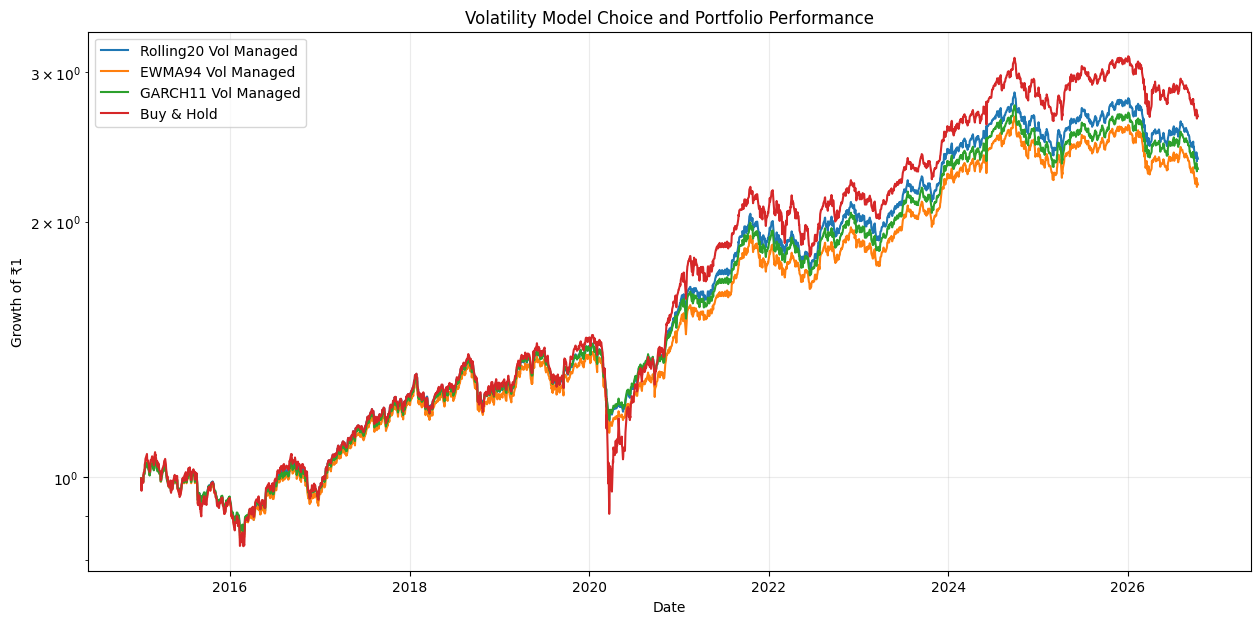

In [184]:
plt.figure(
    figsize=(15, 7)
)

for key, bt in model_backtests.items():

    plt.plot(
        bt.index,
        bt["Wealth"],
        label=display_names[key]
    )

plt.title(
    "Volatility Model Choice and Portfolio Performance"
)

plt.xlabel("Date")
plt.ylabel("Growth of ₹1")

plt.yscale("log")

plt.legend()
plt.grid(alpha=0.25)

plt.show()

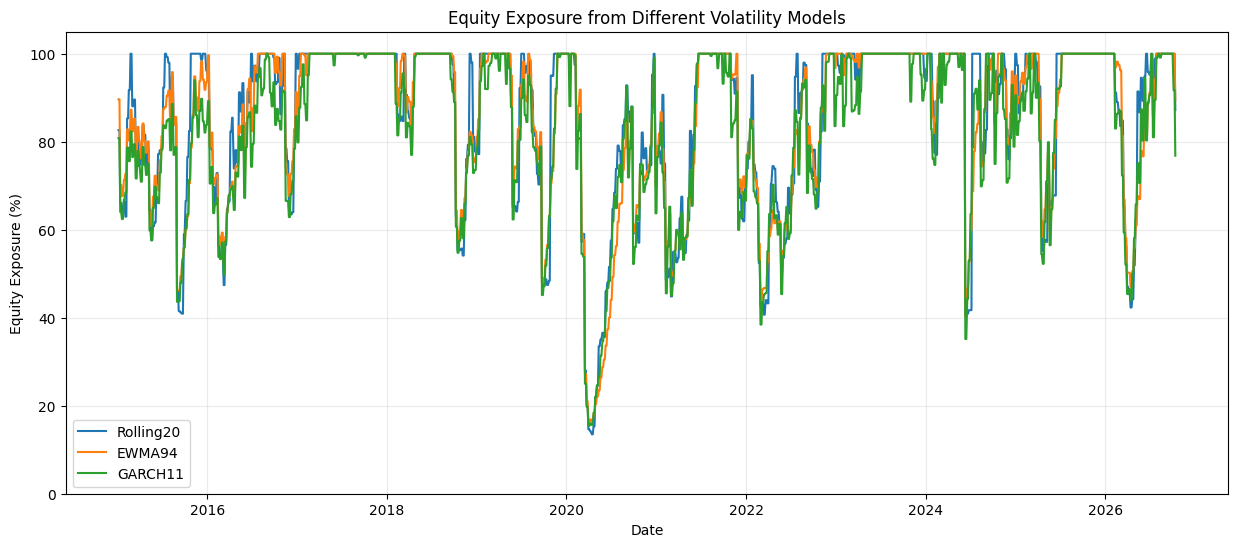

In [185]:
plt.figure(
    figsize=(15, 6)
)

for model_name in [
    "Rolling20",
    "EWMA94",
    "GARCH11"
]:

    bt = model_backtests[
        model_name
    ]

    plt.plot(
        bt.index,
        100 * bt["Weight"],
        label=model_name
    )

plt.title(
    "Equity Exposure from Different Volatility Models"
)

plt.xlabel("Date")
plt.ylabel("Equity Exposure (%)")

plt.ylim(0, 105)

plt.legend()
plt.grid(alpha=0.25)

plt.show()

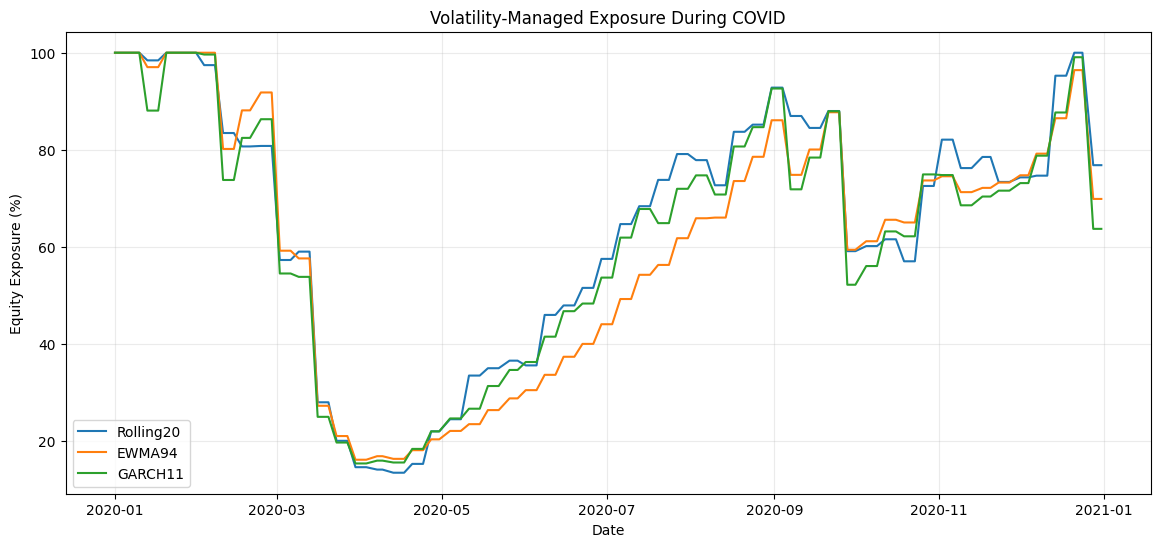

In [186]:
plt.figure(
    figsize=(14, 6)
)

for model_name in [
    "Rolling20",
    "EWMA94",
    "GARCH11"
]:

    bt = model_backtests[
        model_name
    ].loc[
        "2020-01-01":
        "2020-12-31"
    ]

    plt.plot(
        bt.index,
        100 * bt["Weight"],
        label=model_name
    )

plt.title(
    "Volatility-Managed Exposure During COVID"
)

plt.xlabel("Date")
plt.ylabel("Equity Exposure (%)")

plt.legend()
plt.grid(alpha=0.25)

plt.show()

In [187]:
def calendar_year_strategy_stats(
    backtest
):
    rows = []

    for year, group in backtest.groupby(
        backtest.index.year
    ):

        r = group[
            "Portfolio_Return"
        ]

        wealth = (
            1 + r
        ).cumprod()

        total_return = (
            wealth.iloc[-1] - 1
        )

        peak = wealth.cummax()

        drawdown = (
            wealth / peak - 1
        )

        rows.append({
            "Year": year,
            "Return": total_return,
            "Max_Drawdown":
                drawdown.min()
        })

    return pd.DataFrame(
        rows
    ).set_index("Year")

In [188]:
yearly_returns = pd.DataFrame()

for model_name in [
    "Rolling20",
    "EWMA94",
    "GARCH11",
    "BuyHold"
]:

    stats_year = (
        calendar_year_strategy_stats(
            model_backtests[
                model_name
            ]
        )
    )

    yearly_returns[
        model_name
    ] = stats_year[
        "Return"
    ]

In [189]:
display(
    (
        100 *
        yearly_returns
    ).round(2)
)

,Rolling20,EWMA94,GARCH11,BuyHold
Year,,,,
2015,-5.24,-5.59,-5.03,-5.40
2016,2.82,1.25,2.25,3.01
2017,28.62,28.37,27.85,28.65
2018,2.10,2.16,3.15,3.15
2019,10.63,10.34,10.48,12.02
2020,11.97,8.64,10.57,14.90
2021,21.32,20.00,19.79,24.12
2022,5.68,5.13,5.04,4.33
2023,19.77,19.96,19.63,20.03


In [190]:
def run_backtest_drift_aware(
    equity_return,
    rf_return,
    target_weight,
    rebalance_mask,
    cost_bps=5,
    execution_lag=1
):
    """
    Drift-aware equity/cash backtest.

    target_weight[t]:
        Target selected using information through date t.

    rebalance_mask[t]:
        True if a portfolio decision/rebalance is made at t.

    execution_lag=1:
        Decision made at t is first applied to the next
        trading day's return.

    Between rebalance dates, the equity weight is allowed
    to drift naturally with equity and cash returns.
    """

    df = pd.DataFrame({
        "Equity_Return": equity_return,
        "RF_Return": rf_return,
        "Decision_Target": target_weight,
        "Decision_Rebalance": rebalance_mask
    }).copy()

    df["Execution_Target"] = (
        df["Decision_Target"]
        .shift(execution_lag)
    )

    df["Execution_Rebalance"] = (
        df["Decision_Rebalance"]
        .shift(execution_lag)
        .fillna(False)
        .astype(bool)
    )

    df = df.dropna(
        subset=[
            "Equity_Return",
            "RF_Return"
        ]
    )

    # Find first day on which this strategy can actually trade.
    valid_start = (
        df["Execution_Rebalance"]
        &
        df["Execution_Target"].notna()
    )

    if not valid_start.any():
        raise ValueError(
            "Strategy never reaches a valid rebalance date."
        )

    first_date = valid_start[
        valid_start
    ].index[0]

    df = df.loc[first_date:].copy()

    cost_rate = cost_bps / 10_000

    current_weight = 0.0
    wealth = 1.0

    records = []

    for date, row in df.iterrows():

        equity_r = row["Equity_Return"]
        rf_r = row["RF_Return"]

        pre_trade_weight = current_weight

        # -----------------------------
        # Rebalance only when scheduled
        # -----------------------------

        if (
            row["Execution_Rebalance"]
            and
            pd.notna(
                row["Execution_Target"]
            )
        ):

            target = float(
                np.clip(
                    row[
                        "Execution_Target"
                    ],
                    0.0,
                    1.0
                )
            )

            turnover = abs(
                target -
                pre_trade_weight
            )

            weight_during_day = target

        else:

            turnover = 0.0

            weight_during_day = (
                pre_trade_weight
            )

        # -----------------------------
        # Trading cost
        # -----------------------------

        transaction_cost = (
            cost_rate *
            turnover
        )

        # -----------------------------
        # Portfolio return
        # -----------------------------

        gross_portfolio_return = (
            weight_during_day
            * equity_r
            +
            (
                1 -
                weight_during_day
            )
            * rf_r
        )

        portfolio_return = (
            gross_portfolio_return
            -
            transaction_cost
        )

        wealth *= (
            1 +
            portfolio_return
        )

        # -----------------------------
        # Weight drift after returns
        # -----------------------------

        equity_value = (
            weight_during_day
            *
            (1 + equity_r)
        )

        cash_value = (
            (1 - weight_during_day)
            *
            (1 + rf_r)
        )

        gross_value = (
            equity_value +
            cash_value
        )

        if gross_value <= 0:
            raise ValueError(
                "Portfolio gross value became non-positive."
            )

        end_weight = (
            equity_value /
            gross_value
        )

        records.append({
            "Date": date,
            "Target_Weight":
                row["Execution_Target"],

            "Rebalanced":
                bool(
                    row[
                        "Execution_Rebalance"
                    ]
                ),

            "Pre_Trade_Weight":
                pre_trade_weight,

            "Weight":
                weight_during_day,

            "End_Weight":
                end_weight,

            "Turnover":
                turnover,

            "Transaction_Cost":
                transaction_cost,

            "Equity_Return":
                equity_r,

            "RF_Return":
                rf_r,

            "Portfolio_Return":
                portfolio_return,

            "Excess_Return":
                portfolio_return -
                rf_r,

            "Wealth":
                wealth
        })

        current_weight = end_weight

    result = (
        pd.DataFrame(records)
        .set_index("Date")
    )

    result["Peak_Wealth"] = (
        result["Wealth"]
        .cummax()
    )

    result["Drawdown"] = (
        result["Wealth"]
        /
        result["Peak_Wealth"]
        - 1
    )

    return result

In [191]:
def get_week_end_mask(index):

    weeks = pd.Series(
        index.to_period("W-FRI"),
        index=index
    )

    return (
        weeks != weeks.shift(-1)
    )

In [192]:
strategy_data = pd.DataFrame(
    index=nifty.index
)

strategy_data["Price"] = (
    nifty["Price"]
)

strategy_data["Equity_Return"] = (
    nifty["Return"]
)

strategy_data["RF_Return"] = (
    nifty["RF_Return"]
)

strategy_data["EWMA_Ann_Vol"] = (
    ewma94_vol_annual
)

In [193]:
strategy_data["MA200"] = (
    strategy_data["Price"]
    .rolling(200)
    .mean()
)

In [194]:
strategy_data["Trend_Raw"] = np.where(
    strategy_data[
        "MA200"
    ].notna(),

    (
        strategy_data["Price"]
        >
        strategy_data["MA200"]
    ).astype(float),

    np.nan
)

In [195]:
strategy_data["Vol_Raw"] = (
    0.12 /
    strategy_data["EWMA_Ann_Vol"]
).clip(
    lower=0,
    upper=1
)

In [196]:
strategy_data["TrendVol_Raw"] = (
    strategy_data["Trend_Raw"]
    *
    strategy_data["Vol_Raw"]
)

In [197]:
strategy_data["Week_End"] = (
    get_week_end_mask(
        strategy_data.index
    )
)

In [198]:
valid_for_all = (
    strategy_data[
        "Trend_Raw"
    ].notna()
    &
    strategy_data[
        "Vol_Raw"
    ].notna()
    &
    strategy_data[
        "Week_End"
    ]
)

common_decision_start = (
    strategy_data.index[
        valid_for_all
    ][0]
)

print(
    "Common decision start:",
    common_decision_start
)

Common decision start: 2008-07-11 00:00:00


In [199]:
sd = strategy_data.loc[
    common_decision_start:
].copy()

In [200]:
buyhold_mask = pd.Series(
    False,
    index=sd.index
)

buyhold_mask.iloc[0] = True

In [201]:
buyhold_target = pd.Series(
    1.0,
    index=sd.index
)

In [202]:
trend_mask = pd.Series(
    True,
    index=sd.index
)

In [206]:
weekly_mask = sd["Week_End"].copy()

In [203]:
bt_buyhold_v2 = (
    run_backtest_drift_aware(
        equity_return=
            sd["Equity_Return"],

        rf_return=
            sd["RF_Return"],

        target_weight=
            buyhold_target,

        rebalance_mask=
            buyhold_mask,

        cost_bps=5,

        execution_lag=1
    )
)

/tmp/ipykernel_921/181666167.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


In [204]:
bt_trend_v2 = (
    run_backtest_drift_aware(
        equity_return=
            sd["Equity_Return"],

        rf_return=
            sd["RF_Return"],

        target_weight=
            sd["Trend_Raw"],

        rebalance_mask=
            trend_mask,

        cost_bps=5,

        execution_lag=1
    )
)

/tmp/ipykernel_921/181666167.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


In [207]:
bt_vol_v2 = (
    run_backtest_drift_aware(
        equity_return=
            sd["Equity_Return"],

        rf_return=
            sd["RF_Return"],

        target_weight=
            sd["Vol_Raw"],

        rebalance_mask=
            weekly_mask,

        cost_bps=5,

        execution_lag=1
    )
)

/tmp/ipykernel_921/181666167.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


In [208]:
bt_trendvol_v2 = (
    run_backtest_drift_aware(
        equity_return=
            sd["Equity_Return"],

        rf_return=
            sd["RF_Return"],

        target_weight=
            sd["TrendVol_Raw"],

        rebalance_mask=
            weekly_mask,

        cost_bps=5,

        execution_lag=1
    )
)

/tmp/ipykernel_921/181666167.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


In [209]:
average_vol_exposure_v2 = (
    bt_vol_v2[
        "Weight"
    ].mean()
)

print(
    f"EWMA average actual exposure: "
    f"{average_vol_exposure_v2:.2%}"
)

EWMA average actual exposure: 78.79%


In [210]:
constant_mix_target = pd.Series(
    average_vol_exposure_v2,
    index=sd.index
)

In [211]:
bt_constant_v2 = (
    run_backtest_drift_aware(
        equity_return=
            sd["Equity_Return"],

        rf_return=
            sd["RF_Return"],

        target_weight=
            constant_mix_target,

        rebalance_mask=
            weekly_mask,

        cost_bps=5,

        execution_lag=1
    )
)

/tmp/ipykernel_921/181666167.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


In [212]:
def performance_metrics_v2(
    backtest,
    name
):

    r = (
        backtest[
            "Portfolio_Return"
        ]
        .dropna()
    )

    excess = (
        backtest[
            "Excess_Return"
        ]
        .loc[r.index]
    )

    n = len(r)

    years = (
        n / 252
    )

    final_wealth = (
        backtest[
            "Wealth"
        ].iloc[-1]
    )

    cagr = (
        final_wealth
        ** (1 / years)
        - 1
    )

    annual_return = (
        r.mean() *
        252
    )

    annual_vol = (
        r.std() *
        np.sqrt(252)
    )

    sharpe = (
        excess.mean()
        /
        excess.std()
        *
        np.sqrt(252)
    )

    max_drawdown = (
        backtest[
            "Drawdown"
        ].min()
    )

    total_turnover = (
        backtest[
            "Turnover"
        ].sum()
    )

    annual_turnover = (
        total_turnover /
        years
    )

    avg_exposure = (
        backtest[
            "Weight"
        ].mean()
    )

    return {
        "Strategy": name,

        "CAGR": cagr,

        "Annual_Return":
            annual_return,

        "Annual_Vol":
            annual_vol,

        "Sharpe":
            sharpe,

        "Max_Drawdown":
            max_drawdown,

        "Final_Wealth":
            final_wealth,

        "Average_Exposure":
            avg_exposure,

        "Annual_Turnover":
            annual_turnover
    }

In [213]:
primary_backtests_v2 = {
    "Buy & Hold":
        bt_buyhold_v2,

    "MA200 Trend":
        bt_trend_v2,

    "EWMA Vol Managed":
        bt_vol_v2,

    "MA200 + EWMA Vol":
        bt_trendvol_v2,

    "Exposure-Matched Mix":
        bt_constant_v2
}

In [214]:
rows = []

for name, bt in (
    primary_backtests_v2.items()
):

    rows.append(
        performance_metrics_v2(
            bt,
            name
        )
    )


primary_results_v2 = (
    pd.DataFrame(rows)
    .set_index("Strategy")
)

In [215]:
primary_readable_v2 = (
    primary_results_v2.copy()
)

for col in [
    "CAGR",
    "Annual_Return",
    "Annual_Vol",
    "Max_Drawdown",
    "Average_Exposure",
    "Annual_Turnover"
]:

    primary_readable_v2[
        col
    ] *= 100

In [216]:
display(
    primary_readable_v2[
        [
            "CAGR",
            "Annual_Vol",
            "Sharpe",
            "Max_Drawdown",
            "Average_Exposure",
            "Annual_Turnover",
            "Final_Wealth"
        ]
    ].round(3)
)

,CAGR,Annual_Vol,Sharpe,Max_Drawdown,Average_Exposure,Annual_Turnover,Final_Wealth
Strategy,,,,,,,
Buy & Hold,10.101,19.499,0.292,-45.368,100.000,5.633,5.520
MA200 Trend,8.236,12.917,0.226,-20.041,71.368,811.086,4.076
EWMA Vol Managed,8.121,11.946,0.226,-19.641,78.792,211.355,4.000
MA200 + EWMA Vol,7.425,9.739,0.186,-15.728,60.331,430.378,3.567
Exposure-Matched Mix,9.535,15.346,0.291,-37.385,78.794,20.897,5.038


In [217]:
model_df = pd.DataFrame(
    index=nifty.index
)

model_df["Equity_Return"] = (
    nifty["Return"]
)

model_df["RF_Return"] = (
    nifty["RF_Return"]
)

model_df["Rolling20"] = (
    rolling20_vol_annual
)

model_df["EWMA94"] = (
    ewma94_vol_annual
)

model_df["GARCH11"] = (
    garch11_vol_annual
)

model_df = (
    model_df
    .loc["2015-01-01":]
    .copy()
)

model_df["Week_End"] = (
    get_week_end_mask(
        model_df.index
    )
)

In [218]:
for model in [
    "Rolling20",
    "EWMA94",
    "GARCH11"
]:

    model_df[
        f"{model}_Target"
    ] = (
        0.12 /
        model_df[model]
    ).clip(
        0,
        1
    )

In [219]:
common_valid = (
    model_df[
        [
            "Rolling20_Target",
            "EWMA94_Target",
            "GARCH11_Target"
        ]
    ].notna().all(axis=1)
    &
    model_df["Week_End"]
)

model_start = (
    model_df.index[
        common_valid
    ][0]
)

md = model_df.loc[
    model_start:
].copy()

print(
    "Model comparison decision start:",
    model_start
)

Model comparison decision start: 2015-01-02 00:00:00


In [220]:
model_bt_v2 = {}

for model in [
    "Rolling20",
    "EWMA94",
    "GARCH11"
]:

    model_bt_v2[model] = (
        run_backtest_drift_aware(
            equity_return=
                md["Equity_Return"],

            rf_return=
                md["RF_Return"],

            target_weight=
                md[
                    f"{model}_Target"
                ],

            rebalance_mask=
                md["Week_End"],

            cost_bps=5,

            execution_lag=1
        )
    )

/tmp/ipykernel_921/181666167.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_921/181666167.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_921/181666167.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


In [221]:
bh_mask = pd.Series(
    False,
    index=md.index
)

bh_mask.iloc[0] = True

bh_target = pd.Series(
    1.0,
    index=md.index
)

model_bt_v2["BuyHold"] = (
    run_backtest_drift_aware(
        equity_return=
            md["Equity_Return"],

        rf_return=
            md["RF_Return"],

        target_weight=
            bh_target,

        rebalance_mask=
            bh_mask,

        cost_bps=5,

        execution_lag=1
    )
)

/tmp/ipykernel_921/181666167.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


In [222]:
model_rows_v2 = []

names_v2 = {
    "Rolling20":
        "Rolling20 Vol Managed",

    "EWMA94":
        "EWMA94 Vol Managed",

    "GARCH11":
        "GARCH11 Vol Managed",

    "BuyHold":
        "Buy & Hold"
}

for key, bt in model_bt_v2.items():

    model_rows_v2.append(
        performance_metrics_v2(
            bt,
            names_v2[key]
        )
    )


model_results_v2 = (
    pd.DataFrame(
        model_rows_v2
    )
    .set_index("Strategy")
)

In [223]:
model_readable_v2 = (
    model_results_v2.copy()
)

for col in [
    "CAGR",
    "Annual_Return",
    "Annual_Vol",
    "Max_Drawdown",
    "Average_Exposure",
    "Annual_Turnover"
]:

    model_readable_v2[
        col
    ] *= 100


display(
    model_readable_v2[
        [
            "CAGR",
            "Annual_Vol",
            "Sharpe",
            "Max_Drawdown",
            "Average_Exposure",
            "Annual_Turnover",
            "Final_Wealth"
        ]
    ].round(3)
)

,CAGR,Annual_Vol,Sharpe,Max_Drawdown,Average_Exposure,Annual_Turnover,Final_Wealth
Strategy,,,,,,,
Rolling20 Vol Managed,7.790,11.895,0.200,-18.983,86.183,234.446,2.370
EWMA94 Vol Managed,7.137,11.833,0.150,-19.641,85.480,212.291,2.210
GARCH11 Vol Managed,7.533,11.457,0.183,-18.507,83.330,281.414,2.305
Buy & Hold,8.888,16.161,0.248,-38.440,100.000,8.696,2.662


In [224]:
# ============================================================
# PRIMARY FIVE-STRATEGY RESULTS
# ============================================================

primary_backtests_v2 = {
    "Buy & Hold": bt_buyhold_v2,
    "MA200 Trend": bt_trend_v2,
    "EWMA Vol Managed": bt_vol_v2,
    "MA200 + EWMA Vol": bt_trendvol_v2,
    "Exposure-Matched Mix": bt_constant_v2
}

# Calculate metrics
rows = []

for name, bt in primary_backtests_v2.items():
    rows.append(
        performance_metrics_v2(
            bt,
            name
        )
    )

primary_results_v2 = (
    pd.DataFrame(rows)
    .set_index("Strategy")
)

# Make a readable copy
primary_readable_v2 = primary_results_v2.copy()

# Convert relevant quantities to percentages
for col in [
    "CAGR",
    "Annual_Return",
    "Annual_Vol",
    "Max_Drawdown",
    "Average_Exposure",
    "Annual_Turnover"
]:
    primary_readable_v2[col] *= 100

# DISPLAY THE RESULT
display(
    primary_readable_v2[
        [
            "CAGR",
            "Annual_Vol",
            "Sharpe",
            "Max_Drawdown",
            "Average_Exposure",
            "Annual_Turnover",
            "Final_Wealth"
        ]
    ].round(3)
)

,CAGR,Annual_Vol,Sharpe,Max_Drawdown,Average_Exposure,Annual_Turnover,Final_Wealth
Strategy,,,,,,,
Buy & Hold,10.101,19.499,0.292,-45.368,100.000,5.633,5.520
MA200 Trend,8.236,12.917,0.226,-20.041,71.368,811.086,4.076
EWMA Vol Managed,8.121,11.946,0.226,-19.641,78.792,211.355,4.000
MA200 + EWMA Vol,7.425,9.739,0.186,-15.728,60.331,430.378,3.567
Exposure-Matched Mix,9.535,15.346,0.291,-37.385,78.794,20.897,5.038


nnext

In [225]:
def align_backtests(bt_a, bt_b):

    common_index = (
        bt_a.index
        .intersection(bt_b.index)
    )

    a = bt_a.loc[common_index].copy()
    b = bt_b.loc[common_index].copy()

    return a, b

In [226]:
def annualized_sharpe(
    portfolio_returns,
    rf_returns,
    trading_days=252
):
    portfolio_returns = np.asarray(
        portfolio_returns
    )

    rf_returns = np.asarray(
        rf_returns
    )

    excess = (
        portfolio_returns
        -
        rf_returns
    )

    if np.std(excess, ddof=1) == 0:
        return np.nan

    return (
        np.mean(excess)
        /
        np.std(excess, ddof=1)
        *
        np.sqrt(trading_days)
    )

In [227]:
def circular_block_indices(
    n,
    block_length,
    rng
):
    """
    Generate n bootstrap indices by sampling
    consecutive circular blocks.

    Example:
        n = 100
        block_length = 15

    Randomly choose starting locations and take
    15 consecutive observations at a time.

    If a block reaches the end, it wraps around.
    """

    indices = []

    while len(indices) < n:

        start = rng.integers(
            0,
            n
        )

        block = (
            start
            +
            np.arange(block_length)
        ) % n

        indices.extend(
            block.tolist()
        )

    return np.array(
        indices[:n]
    )

In [228]:
def paired_sharpe_bootstrap(
    bt_a,
    bt_b,
    block_length=15,
    n_bootstrap=5000,
    seed=42
):
    """
    Paired circular block bootstrap for:

        Sharpe(A) - Sharpe(B)

    The same block indices are used for both
    strategies and the risk-free series.
    """

    a, b = align_backtests(
        bt_a,
        bt_b
    )

    # Their RF series should be the same.
    rf_a = a["RF_Return"].to_numpy()
    rf_b = b["RF_Return"].to_numpy()

    if not np.allclose(
        rf_a,
        rf_b
    ):
        raise ValueError(
            "Risk-free returns differ between backtests."
        )

    ra = (
        a["Portfolio_Return"]
        .to_numpy()
    )

    rb = (
        b["Portfolio_Return"]
        .to_numpy()
    )

    rf = rf_a

    n = len(ra)

    # Original-sample Sharpes
    sharpe_a = annualized_sharpe(
        ra,
        rf
    )

    sharpe_b = annualized_sharpe(
        rb,
        rf
    )

    observed_difference = (
        sharpe_a - sharpe_b
    )

    rng = np.random.default_rng(
        seed
    )

    bootstrap_differences = np.empty(
        n_bootstrap
    )

    bootstrap_sharpe_a = np.empty(
        n_bootstrap
    )

    bootstrap_sharpe_b = np.empty(
        n_bootstrap
    )

    for i in range(n_bootstrap):

        idx = circular_block_indices(
            n=n,
            block_length=block_length,
            rng=rng
        )

        sr_a = annualized_sharpe(
            ra[idx],
            rf[idx]
        )

        sr_b = annualized_sharpe(
            rb[idx],
            rf[idx]
        )

        bootstrap_sharpe_a[i] = sr_a
        bootstrap_sharpe_b[i] = sr_b

        bootstrap_differences[i] = (
            sr_a - sr_b
        )

    lower = np.percentile(
        bootstrap_differences,
        2.5
    )

    upper = np.percentile(
        bootstrap_differences,
        97.5
    )

    probability_a_better = np.mean(
        bootstrap_differences > 0
    )

    return {
        "Sharpe_A": sharpe_a,
        "Sharpe_B": sharpe_b,
        "Observed_Difference":
            observed_difference,

        "CI_2.5%":
            lower,

        "CI_97.5%":
            upper,

        "Bootstrap_P_A_gt_B":
            probability_a_better,

        "Bootstrap_Differences":
            bootstrap_differences,

        "Bootstrap_Sharpe_A":
            bootstrap_sharpe_a,

        "Bootstrap_Sharpe_B":
            bootstrap_sharpe_b
    }

In [229]:
boot_ewma_vs_bh = (
    paired_sharpe_bootstrap(
        bt_vol_v2,
        bt_buyhold_v2,
        block_length=15,
        n_bootstrap=5000,
        seed=42
    )
)

In [230]:
print(
    "EWMA Vol Managed vs Buy & Hold"
)

print(
    f"EWMA Sharpe: "
    f"{boot_ewma_vs_bh['Sharpe_A']:.3f}"
)

print(
    f"Buy & Hold Sharpe: "
    f"{boot_ewma_vs_bh['Sharpe_B']:.3f}"
)

print(
    f"Observed difference: "
    f"{boot_ewma_vs_bh['Observed_Difference']:.3f}"
)

print(
    "95% bootstrap CI: "
    f"[{boot_ewma_vs_bh['CI_2.5%']:.3f}, "
    f"{boot_ewma_vs_bh['CI_97.5%']:.3f}]"
)

print(
    "P(EWMA Sharpe > BuyHold Sharpe): "
    f"{boot_ewma_vs_bh['Bootstrap_P_A_gt_B']:.3f}"
)

EWMA Vol Managed vs Buy & Hold
EWMA Sharpe: 0.226
Buy & Hold Sharpe: 0.292
Observed difference: -0.067
95% bootstrap CI: [-0.278, 0.141]
P(EWMA Sharpe > BuyHold Sharpe): 0.254


In [231]:
boot_ewma_vs_mix = (
    paired_sharpe_bootstrap(
        bt_vol_v2,
        bt_constant_v2,
        block_length=15,
        n_bootstrap=5000,
        seed=43
    )
)

In [232]:
print(
    "EWMA Vol Managed vs Exposure-Matched Mix"
)

print(
    f"EWMA Sharpe: "
    f"{boot_ewma_vs_mix['Sharpe_A']:.3f}"
)

print(
    f"Constant Mix Sharpe: "
    f"{boot_ewma_vs_mix['Sharpe_B']:.3f}"
)

print(
    f"Observed difference: "
    f"{boot_ewma_vs_mix['Observed_Difference']:.3f}"
)

print(
    "95% bootstrap CI: "
    f"[{boot_ewma_vs_mix['CI_2.5%']:.3f}, "
    f"{boot_ewma_vs_mix['CI_97.5%']:.3f}]"
)

print(
    "P(EWMA Sharpe > Constant Mix Sharpe): "
    f"{boot_ewma_vs_mix['Bootstrap_P_A_gt_B']:.3f}"
)

EWMA Vol Managed vs Exposure-Matched Mix
EWMA Sharpe: 0.226
Constant Mix Sharpe: 0.291
Observed difference: -0.065
95% bootstrap CI: [-0.264, 0.136]
P(EWMA Sharpe > Constant Mix Sharpe): 0.259


In [233]:
boot_trendvol_vs_bh = (
    paired_sharpe_bootstrap(
        bt_trendvol_v2,
        bt_buyhold_v2,
        block_length=15,
        n_bootstrap=5000,
        seed=44
    )
)

In [234]:
print(
    "Trend + EWMA Vol vs Buy & Hold"
)

print(
    f"TrendVol Sharpe: "
    f"{boot_trendvol_vs_bh['Sharpe_A']:.3f}"
)

print(
    f"BuyHold Sharpe: "
    f"{boot_trendvol_vs_bh['Sharpe_B']:.3f}"
)

print(
    f"Observed difference: "
    f"{boot_trendvol_vs_bh['Observed_Difference']:.3f}"
)

print(
    "95% bootstrap CI: "
    f"[{boot_trendvol_vs_bh['CI_2.5%']:.3f}, "
    f"{boot_trendvol_vs_bh['CI_97.5%']:.3f}]"
)

Trend + EWMA Vol vs Buy & Hold
TrendVol Sharpe: 0.186
BuyHold Sharpe: 0.292
Observed difference: -0.106
95% bootstrap CI: [-0.522, 0.301]


In [235]:
bootstrap_results = pd.DataFrame([
    {
        "Comparison":
            "EWMA Vol - BuyHold",

        "Sharpe_Difference":
            boot_ewma_vs_bh[
                "Observed_Difference"
            ],

        "CI_Lower":
            boot_ewma_vs_bh[
                "CI_2.5%"
            ],

        "CI_Upper":
            boot_ewma_vs_bh[
                "CI_97.5%"
            ],

        "P_First_Better":
            boot_ewma_vs_bh[
                "Bootstrap_P_A_gt_B"
            ]
    },

    {
        "Comparison":
            "EWMA Vol - Exposure Mix",

        "Sharpe_Difference":
            boot_ewma_vs_mix[
                "Observed_Difference"
            ],

        "CI_Lower":
            boot_ewma_vs_mix[
                "CI_2.5%"
            ],

        "CI_Upper":
            boot_ewma_vs_mix[
                "CI_97.5%"
            ],

        "P_First_Better":
            boot_ewma_vs_mix[
                "Bootstrap_P_A_gt_B"
            ]
    },

    {
        "Comparison":
            "Trend+Vol - BuyHold",

        "Sharpe_Difference":
            boot_trendvol_vs_bh[
                "Observed_Difference"
            ],

        "CI_Lower":
            boot_trendvol_vs_bh[
                "CI_2.5%"
            ],

        "CI_Upper":
            boot_trendvol_vs_bh[
                "CI_97.5%"
            ],

        "P_First_Better":
            boot_trendvol_vs_bh[
                "Bootstrap_P_A_gt_B"
            ]
    }
])

display(
    bootstrap_results.round(4)
)

,Comparison,Sharpe_Difference,CI_Lower,CI_Upper,P_First_Better
0,EWMA Vol - BuyHold,-0.0666,-0.2776,0.1405,0.2538
1,EWMA Vol - Exposure Mix,-0.0649,-0.2642,0.1359,0.2588
2,Trend+Vol - BuyHold,-0.1064,-0.5216,0.3008,0.2798


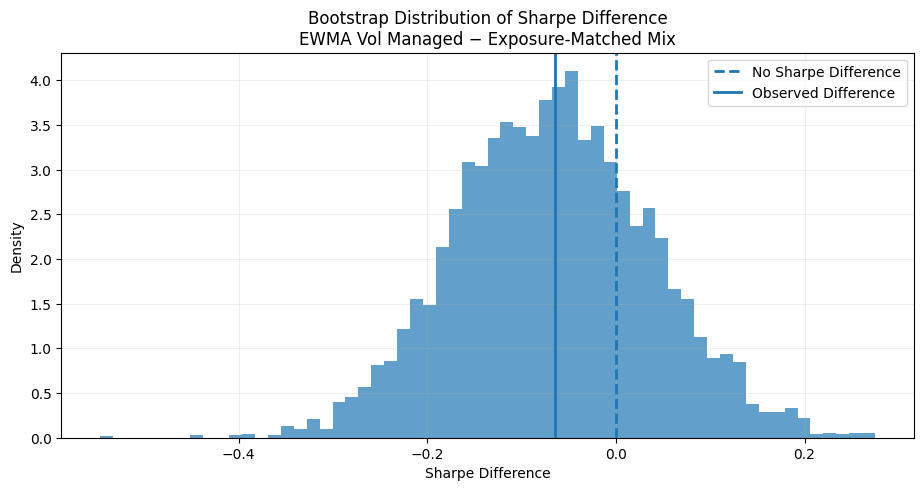

In [236]:
diffs = (
    boot_ewma_vs_mix[
        "Bootstrap_Differences"
    ]
)

plt.figure(
    figsize=(11, 5)
)

plt.hist(
    diffs,
    bins=60,
    density=True,
    alpha=0.7
)

plt.axvline(
    0,
    linestyle="--",
    linewidth=2,
    label="No Sharpe Difference"
)

plt.axvline(
    boot_ewma_vs_mix[
        "Observed_Difference"
    ],
    linewidth=2,
    label="Observed Difference"
)

plt.title(
    "Bootstrap Distribution of Sharpe Difference\n"
    "EWMA Vol Managed − Exposure-Matched Mix"
)

plt.xlabel(
    "Sharpe Difference"
)

plt.ylabel(
    "Density"
)

plt.legend()
plt.grid(alpha=0.2)

plt.show()

In [237]:
# ============================================================
# ROBUSTNESS CONFIGURATION
# ============================================================

VOL_TARGETS = [0.10, 0.12, 0.15]
MA_WINDOWS = [100, 200]
COSTS_BPS = [0, 5, 10, 20]
EXECUTION_LAGS = [1, 2]

In [238]:
for ma_window in MA_WINDOWS:

    strategy_data[
        f"MA{ma_window}"
    ] = (
        strategy_data["Price"]
        .rolling(ma_window)
        .mean()
    )

    strategy_data[
        f"Trend{ma_window}_Raw"
    ] = np.where(
        strategy_data[
            f"MA{ma_window}"
        ].notna(),

        (
            strategy_data["Price"]
            >
            strategy_data[
                f"MA{ma_window}"
            ]
        ).astype(float),

        np.nan
    )

In [239]:
robustness_valid = (
    strategy_data[
        "Trend200_Raw"
    ].notna()
    &
    strategy_data[
        "EWMA_Ann_Vol"
    ].notna()
    &
    strategy_data[
        "Week_End"
    ]
)

ROBUSTNESS_START = (
    strategy_data.index[
        robustness_valid
    ][0]
)

print(
    "Robustness common start:",
    ROBUSTNESS_START
)

Robustness common start: 2008-07-11 00:00:00


In [240]:
robust = (
    strategy_data
    .loc[ROBUSTNESS_START:]
    .copy()
)

weekly_mask_robust = (
    robust["Week_End"]
)

In [241]:
vol_robustness_rows = []

for vol_target in VOL_TARGETS:

    raw_target = (
        vol_target
        /
        robust["EWMA_Ann_Vol"]
    ).clip(
        lower=0,
        upper=1
    )

    for cost_bps in COSTS_BPS:

        for lag in EXECUTION_LAGS:

            bt = run_backtest_drift_aware(
                equity_return=
                    robust["Equity_Return"],

                rf_return=
                    robust["RF_Return"],

                target_weight=
                    raw_target,

                rebalance_mask=
                    weekly_mask_robust,

                cost_bps=
                    cost_bps,

                execution_lag=
                    lag
            )

            metrics = (
                performance_metrics_v2(
                    bt,
                    "EWMA Vol"
                )
            )

            vol_robustness_rows.append({
                "Vol_Target":
                    vol_target,

                "Cost_bps":
                    cost_bps,

                "Lag":
                    lag,

                "CAGR":
                    metrics["CAGR"],

                "Annual_Vol":
                    metrics["Annual_Vol"],

                "Sharpe":
                    metrics["Sharpe"],

                "Max_Drawdown":
                    metrics["Max_Drawdown"],

                "Average_Exposure":
                    metrics[
                        "Average_Exposure"
                    ],

                "Annual_Turnover":
                    metrics[
                        "Annual_Turnover"
                    ]
            })

/tmp/ipykernel_921/181666167.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_921/181666167.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_921/181666167.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_921/181666167.py:41: FutureWarning

In [242]:
vol_robustness = pd.DataFrame(
    vol_robustness_rows
)

display(
    vol_robustness.head()
)

,Vol_Target,Cost_bps,Lag,CAGR,Annual_Vol,Sharpe,Max_Drawdown,Average_Exposure,Annual_Turnover
0,0.1,0,1,0.082225,0.103360,0.252522,-0.166196,0.693420,2.334751
1,0.1,0,2,0.083902,0.104003,0.266496,-0.189043,0.693429,2.347627
2,0.1,5,1,0.080963,0.103357,0.241235,-0.166619,0.693420,2.334751
3,0.1,5,2,0.082631,0.104005,0.255203,-0.189437,0.693429,2.347627
4,0.1,10,1,0.079703,0.103354,0.229946,-0.167042,0.693420,2.334751


In [243]:
vol_robustness_readable = (
    vol_robustness.copy()
)

for col in [
    "Vol_Target",
    "CAGR",
    "Annual_Vol",
    "Max_Drawdown",
    "Average_Exposure",
    "Annual_Turnover"
]:

    vol_robustness_readable[
        col
    ] *= 100

In [244]:
vol_robustness_readable = (
    vol_robustness.copy()
)

for col in [
    "Vol_Target",
    "CAGR",
    "Annual_Vol",
    "Max_Drawdown",
    "Average_Exposure",
    "Annual_Turnover"
]:

    vol_robustness_readable[
        col
    ] *= 100

In [245]:
display(
    vol_robustness_readable.round(3)
)

,Vol_Target,Cost_bps,Lag,CAGR,Annual_Vol,Sharpe,Max_Drawdown,Average_Exposure,Annual_Turnover
0,10.0,0,1,8.223,10.336,0.253,-16.620,69.342,233.475
1,10.0,0,2,8.390,10.400,0.266,-18.904,69.343,234.763
2,10.0,5,1,8.096,10.336,0.241,-16.662,69.342,233.475
3,10.0,5,2,8.263,10.401,0.255,-18.944,69.343,234.763
4,10.0,10,1,7.970,10.335,0.230,-16.704,69.342,233.475
5,10.0,10,2,8.136,10.401,0.244,-18.983,69.343,234.763
6,10.0,20,1,7.719,10.335,0.207,-16.789,69.342,233.475
7,10.0,20,2,7.882,10.402,0.221,-19.062,69.343,234.763
8,12.0,0,1,8.235,11.946,0.235,-19.601,78.792,211.355
9,12.0,0,2,8.375,12.018,0.245,-22.272,78.792,212.321


In [246]:
vol_target_summary = (
    vol_robustness
    .groupby("Vol_Target")
    [
        [
            "CAGR",
            "Annual_Vol",
            "Sharpe",
            "Max_Drawdown",
            "Average_Exposure"
        ]
    ]
    .mean()
)

display(
    vol_target_summary
)

,CAGR,Annual_Vol,Sharpe,Max_Drawdown,Average_Exposure
Vol_Target,,,,,
0.10,0.080849,0.103682,0.239749,-0.178335,0.693425
0.12,0.081047,0.119824,0.224058,-0.210035,0.787923
0.15,0.085637,0.137313,0.242797,-0.249398,0.877567


In [247]:
cost_sensitivity = (
    vol_robustness[
        (
            vol_robustness[
                "Vol_Target"
            ] == 0.12
        )
        &
        (
            vol_robustness[
                "Lag"
            ] == 1
        )
    ]
    [
        [
            "Cost_bps",
            "CAGR",
            "Sharpe",
            "Annual_Turnover"
        ]
    ]
)

display(
    cost_sensitivity.round(4)
)

,Cost_bps,CAGR,Sharpe,Annual_Turnover
8,0,0.0824,0.2345,2.1135
10,5,0.0812,0.2257,2.1135
12,10,0.0801,0.2168,2.1135
14,20,0.0778,0.1991,2.1135


In [248]:
lag_sensitivity = (
    vol_robustness[
        (
            vol_robustness[
                "Vol_Target"
            ] == 0.12
        )
        &
        (
            vol_robustness[
                "Cost_bps"
            ] == 5
        )
    ]
    [
        [
            "Lag",
            "CAGR",
            "Annual_Vol",
            "Sharpe",
            "Max_Drawdown"
        ]
    ]
)

display(
    lag_sensitivity.round(4)
)

,Lag,CAGR,Annual_Vol,Sharpe,Max_Drawdown
10,1,0.0812,0.1195,0.2257,-0.1964
11,2,0.0826,0.1202,0.2357,-0.2231


In [249]:
trend_robustness_rows = []

daily_rebalance_mask = pd.Series(
    True,
    index=robust.index
)

for ma_window in MA_WINDOWS:

    target = (
        robust[
            f"Trend{ma_window}_Raw"
        ]
    )

    for cost_bps in COSTS_BPS:

        for lag in EXECUTION_LAGS:

            bt = run_backtest_drift_aware(
                equity_return=
                    robust["Equity_Return"],

                rf_return=
                    robust["RF_Return"],

                target_weight=
                    target,

                rebalance_mask=
                    daily_rebalance_mask,

                cost_bps=
                    cost_bps,

                execution_lag=
                    lag
            )

            metrics = (
                performance_metrics_v2(
                    bt,
                    f"MA{ma_window}"
                )
            )

            trend_robustness_rows.append({
                "MA_Window":
                    ma_window,

                "Cost_bps":
                    cost_bps,

                "Lag":
                    lag,

                "CAGR":
                    metrics["CAGR"],

                "Annual_Vol":
                    metrics["Annual_Vol"],

                "Sharpe":
                    metrics["Sharpe"],

                "Max_Drawdown":
                    metrics["Max_Drawdown"],

                "Average_Exposure":
                    metrics[
                        "Average_Exposure"
                    ],

                "Annual_Turnover":
                    metrics[
                        "Annual_Turnover"
                    ]
            })

/tmp/ipykernel_921/181666167.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_921/181666167.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_921/181666167.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_921/181666167.py:41: FutureWarning

In [250]:
trend_robustness = pd.DataFrame(
    trend_robustness_rows
)

display(
    trend_robustness.round(4)
)

,MA_Window,Cost_bps,Lag,CAGR,Annual_Vol,Sharpe,Max_Drawdown,Average_Exposure,Annual_Turnover
0,100,0,1,0.1148,0.1248,0.4654,-0.1463,0.6591,10.2512
1,100,0,2,0.1069,0.1259,0.4061,-0.1679,0.6593,10.2535
2,100,5,1,0.1091,0.1248,0.4244,-0.1518,0.6591,10.2512
3,100,5,2,0.1012,0.1259,0.3654,-0.1736,0.6593,10.2535
4,100,10,1,0.1034,0.1248,0.3833,-0.1598,0.6591,10.2512
5,100,10,2,0.0956,0.1259,0.3246,-0.1800,0.6593,10.2535
6,100,20,1,0.0921,0.1248,0.3011,-0.1895,0.6591,10.2512
7,100,20,2,0.0844,0.1260,0.2430,-0.1954,0.6593,10.2535
8,200,0,1,0.0868,0.1292,0.2569,-0.1857,0.7137,8.1109
9,200,0,2,0.0888,0.1295,0.2709,-0.2086,0.7138,8.1127


In [251]:
trendvol_robustness_rows = []

for ma_window in MA_WINDOWS:

    trend = (
        robust[
            f"Trend{ma_window}_Raw"
        ]
    )

    for vol_target in VOL_TARGETS:

        vol_target_raw = (
            vol_target
            /
            robust[
                "EWMA_Ann_Vol"
            ]
        ).clip(
            0,
            1
        )

        combined_target = (
            trend *
            vol_target_raw
        )

        for cost_bps in COSTS_BPS:

            for lag in EXECUTION_LAGS:

                bt = (
                    run_backtest_drift_aware(
                        equity_return=
                            robust[
                                "Equity_Return"
                            ],

                        rf_return=
                            robust[
                                "RF_Return"
                            ],

                        target_weight=
                            combined_target,

                        rebalance_mask=
                            weekly_mask_robust,

                        cost_bps=
                            cost_bps,

                        execution_lag=
                            lag
                    )
                )

                metrics = (
                    performance_metrics_v2(
                        bt,
                        "Trend+Vol"
                    )
                )

                trendvol_robustness_rows.append({
                    "MA_Window":
                        ma_window,

                    "Vol_Target":
                        vol_target,

                    "Cost_bps":
                        cost_bps,

                    "Lag":
                        lag,

                    "CAGR":
                        metrics["CAGR"],

                    "Annual_Vol":
                        metrics["Annual_Vol"],

                    "Sharpe":
                        metrics["Sharpe"],

                    "Max_Drawdown":
                        metrics[
                            "Max_Drawdown"
                        ],

                    "Average_Exposure":
                        metrics[
                            "Average_Exposure"
                        ],

                    "Annual_Turnover":
                        metrics[
                            "Annual_Turnover"
                        ]
                })

/tmp/ipykernel_921/181666167.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_921/181666167.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_921/181666167.py:41: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)
/tmp/ipykernel_921/181666167.py:41: FutureWarning

In [252]:
trendvol_robustness = pd.DataFrame(
    trendvol_robustness_rows
)

display(
    trendvol_robustness.head(10)
)

,MA_Window,Vol_Target,Cost_bps,Lag,CAGR,Annual_Vol,Sharpe,Max_Drawdown,Average_Exposure,Annual_Turnover
0,100,0.10,0,1,0.080123,0.081536,0.271475,-0.137867,0.499304,5.072774
1,100,0.10,0,2,0.080983,0.082974,0.277796,-0.146443,0.499370,5.087848
2,100,0.10,5,1,0.077389,0.081524,0.240400,-0.145256,0.499304,5.072774
3,100,0.10,5,2,0.078236,0.082983,0.247111,-0.153987,0.499370,5.087848
4,100,0.10,10,1,0.074660,0.081522,0.209295,-0.152584,0.499304,5.072774
5,100,0.10,10,2,0.075496,0.083000,0.216411,-0.161662,0.499370,5.087848
6,100,0.10,20,1,0.069222,0.081542,0.147032,-0.167689,0.499304,5.072774
7,100,0.10,20,2,0.070034,0.083060,0.155001,-0.176813,0.499370,5.087848
8,100,0.12,0,1,0.081059,0.092608,0.258772,-0.158062,0.559118,5.405018
9,100,0.12,0,2,0.081699,0.094310,0.262084,-0.169817,0.559213,5.416370


In [253]:
block_length_rows = []

for block_length in [10, 15, 40]:

    result = paired_sharpe_bootstrap(
        bt_vol_v2,
        bt_constant_v2,
        block_length=
            block_length,

        n_bootstrap=
            5000,

        seed=
            100 + block_length
    )

    block_length_rows.append({
        "Block_Length":
            block_length,

        "Sharpe_Difference":
            result[
                "Observed_Difference"
            ],

        "CI_Lower":
            result[
                "CI_2.5%"
            ],

        "CI_Upper":
            result[
                "CI_97.5%"
            ],

        "P_EWMA_Better":
            result[
                "Bootstrap_P_A_gt_B"
            ]
    })

In [254]:
block_length_robustness = (
    pd.DataFrame(
        block_length_rows
    )
)

display(
    block_length_robustness.round(4)
)

,Block_Length,Sharpe_Difference,CI_Lower,CI_Upper,P_EWMA_Better
0,10,-0.0649,-0.2698,0.1431,0.2602
1,15,-0.0649,-0.2692,0.1515,0.2606
2,40,-0.0649,-0.2743,0.1460,0.2526


In [255]:
def yearly_performance(backtest):

    rows = []

    for year, group in (
        backtest.groupby(
            backtest.index.year
        )
    ):

        r = (
            group[
                "Portfolio_Return"
            ]
        )

        wealth = (
            1 + r
        ).cumprod()

        annual_return = (
            wealth.iloc[-1] - 1
        )

        peak = (
            wealth.cummax()
        )

        drawdown = (
            wealth / peak - 1
        )

        rows.append({
            "Year":
                year,

            "Return":
                annual_return,

            "Max_Drawdown":
                drawdown.min()
        })

    return (
        pd.DataFrame(rows)
        .set_index("Year")
    )

In [256]:
yearly_primary = {}

for name in [
    "Buy & Hold",
    "EWMA Vol Managed",
    "Exposure-Matched Mix"
]:

    yearly_primary[name] = (
        yearly_performance(
            primary_backtests_v2[
                name
            ]
        )
    )

In [257]:
yearly_return_table = pd.DataFrame({
    name:
        result["Return"]

    for name, result
    in yearly_primary.items()
})

display(
    (
        100 *
        yearly_return_table
    ).round(2)
)

,Buy & Hold,EWMA Vol Managed,Exposure-Matched Mix
Year,,,
2008,-26.95,-7.34,-20.80
2009,75.76,27.50,59.20
2010,17.95,14.58,15.53
2011,-24.62,-15.99,-18.68
2012,27.70,20.13,22.88
2013,6.76,2.48,6.77
2014,31.39,27.70,25.67
2015,-4.06,-4.42,-1.86
2016,3.01,1.29,3.82


In [258]:
yearly_drawdown_table = pd.DataFrame({
    name:
        result["Max_Drawdown"]

    for name, result
    in yearly_primary.items()
})

display(
    (
        100 *
        yearly_drawdown_table
    ).round(2)
)

,Buy & Hold,EWMA Vol Managed,Exposure-Matched Mix
Year,,,
2008,-45.37,-14.56,-37.39
2009,-17.57,-7.25,-13.79
2010,-10.66,-8.23,-8.38
2011,-26.20,-17.05,-20.06
2012,-13.76,-9.18,-10.71
2013,-14.58,-9.60,-11.32
2014,-6.50,-6.50,-5.08
2015,-15.98,-13.83,-12.17
2016,-11.66,-10.77,-8.96


In [259]:
vol_robustness.to_csv(
    PROCESSED_DIR /
    "robustness_vol_target.csv",
    index=False
)

trend_robustness.to_csv(
    PROCESSED_DIR /
    "robustness_trend.csv",
    index=False
)

trendvol_robustness.to_csv(
    PROCESSED_DIR /
    "robustness_trend_vol.csv",
    index=False
)

block_length_robustness.to_csv(
    PROCESSED_DIR /
    "bootstrap_block_robustness.csv",
    index=False
)

yearly_return_table.to_csv(
    PROCESSED_DIR /
    "strategy_yearly_returns.csv"
)

yearly_drawdown_table.to_csv(
    PROCESSED_DIR /
    "strategy_yearly_drawdowns.csv"
)

print("Robustness outputs saved.")

Robustness outputs saved.


In [260]:
display(
    trend_robustness.groupby(
        "MA_Window"
    )[
        [
            "CAGR",
            "Sharpe",
            "Max_Drawdown",
            "Annual_Turnover"
        ]
    ].mean().round(4)
)

,CAGR,Sharpe,Max_Drawdown,Annual_Turnover
MA_Window,,,,
100,0.1009,0.3642,-0.1706,10.2524
200,0.0801,0.2090,-0.2172,8.1118


In [261]:
display(
    trendvol_robustness.groupby(
        [
            "MA_Window",
            "Vol_Target"
        ]
    )[
        [
            "CAGR",
            "Sharpe",
            "Max_Drawdown"
        ]
    ].mean().round(4)
)

CAGR  Sharpe  Max_Drawdown
MA_Window Vol_Target                              
100       0.10        0.0758  0.2206       -0.1553
          0.12        0.0763  0.2097       -0.1778
          0.15        0.0803  0.2341       -0.1869
200       0.10        0.0712  0.1656       -0.1620
          0.12        0.0691  0.1365       -0.1991
          0.15        0.0710  0.1495       -0.2173